# Global AI Jobs 2026 Salary Prediction
### End-to-end machine-learning project: cleaning → EDA → feature engineering → modelling → validation → recommendations

**Dataset:** `global_ai_jobs_2026.csv` (5,000 job postings × 37 columns)
**Task:** supervised regression — predict `Salary_USD`

---
## Table of contents
1. Problem statement
2. Proposed solution
3. Setup & data loading
4. Data audit
5. Deep data cleaning
6. Target-leakage audit (critical)
7. Train / test split (the test set is locked away)
8. Exploratory data analysis & visualisation
9. Feature engineering (with the maths)
10. Feature reduction
11. Scaling / normalisation
12. Modelling (baselines → tuned models → ensemble)
13. Final evaluation on the held-out test set
14. Under-fitting / over-fitting diagnostics
15. Data-leakage verification tests
16. Interpretation & uncertainty (prediction intervals)
17. Recommendations & solution summary

## 1. Problem statement

**Context.** AI roles are among the fastest-growing and most unevenly paid jobs in the world. Compensation teams struggle to benchmark offers, candidates cannot tell whether an offer is fair, and policy makers lack a view of where pay gaps come from (country, seniority, role, industry...).

**Business question.** *Given the attributes of an AI job posting, what salary (USD) should we expect, and which attributes actually drive it?*

**ML formulation.** Supervised **regression**. Target = `Salary_USD` (continuous, right-skewed). Unit of analysis = one job posting.

**Who benefits**
| Stakeholder | Use |
|---|---|
| HR / compensation teams | Benchmark a new role's salary band before publishing it |
| Candidates | Sanity-check an offer against the market |
| Analysts / policy makers | Quantify the pay premium of seniority, geography, role |

**Success criteria (defined *before* modelling)**
* Generalisation: test $R^2$ on $\ln(\text{salary})$ clearly above the mean-predictor baseline, with **train–CV–test gap < 0.03** (no over-fitting).
* Error expressed in business terms: MAE in USD and median absolute percentage error (MdAPE).
* **Zero target leakage** — no feature may contain information that would not exist when a salary is being set.
* Calibrated uncertainty: 90 % prediction intervals that really cover ≈ 90 % of unseen postings.

**Hypotheses to test in EDA**
* H1 – Seniority (`Experience_Level`) is the strongest salary driver.
* H2 – Country / region explains a large share of the remaining variance (cost-of-living & market maturity).
* H3 – Role (`Job_Title`) and industry add smaller but real effects.
* H4 – Company-level descriptors (AI investment, maturity, size) and "soft" metrics (satisfaction, work-life balance) carry little salary information.
* H5 – Some columns are **derived from the target** (`Salary_Min`, `Salary_Max`, `Salary_Category`) and must be removed.

## 2. Proposed solution

A **leakage-safe, reproducible scikit-learn pipeline**:

| Stage | What we do | Why |
|---|---|---|
| Audit & clean | Types, duplicates, missing, logical consistency, outliers | Garbage-in / garbage-out |
| Leakage audit | Find & remove columns that encode the target | Otherwise metrics are fake |
| Split first | 80 / 20 split *before* any EDA/fitting | The test set must stay unseen |
| EDA | Distribution, statistical tests, mutual information, VIF | Understand signal vs. noise |
| Target transform | Model $\ln(\text{Salary})$ | Salary is multiplicative → additive in log space |
| Feature engineering | Ordinal maps, log/sqrt, ratios, skills (multi-hot, IDF rarity), shrinkage target-encoding | Inject domain & mathematical structure |
| Feature reduction | Permutation importance, ablation, Lasso, PCA/Marchenko–Pastur | Remove noise, keep parsimony |
| Scaling | Compare Standard / Robust / MinMax / Yeo-Johnson | Required by linear & distance models |
| Models | Dummy, Ridge, Lasso, ElasticNet, KNN, RF, ExtraTrees, HistGB, XGBoost, LightGBM | Cover bias/variance spectrum |
| Validation | Repeated K-fold, nested CV, learning/validation curves, bias–variance, shuffled-label test, adversarial validation | Prove no over/under-fit, no leakage |
| Uncertainty | Mondrian conformal prediction intervals | Honest error bars |

**Every transformation lives inside a `Pipeline`**, so it is re-fitted on the training fold only in each cross-validation round — this is the main structural defence against leakage.

## 3.Data loading

In [1]:
import os, re, math, time, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

In [2]:
DATA_PATH = "global_ai_jobs_2026.csv"
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
print(f"Loaded {DATA_PATH}  ->  {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head(3).T

Loaded global_ai_jobs_2026.csv  ->  5,000 rows × 37 columns


,0,1,2
Job_ID,AI-03546,AI-01969,AI-02960
Job_Title,Business Intelligence Analyst,Generative AI Engineer,AI Software Engineer
AI_Specialization,Computer Vision,Reinforcement Learning,Deep Learning
Industry,E-commerce,Automotive,Insurance
Company,Alibaba,UiPath,UiPath
Company_Size,Enterprise (5000+),Large (501-5000),Enterprise (5000+)
Country,Israel,United States,United States
Continent,Asia,North America,North America
Education_Required,Bachelor's,Master's,Postdoctoral
Experience_Level,Executive,Executive,Executive


## 4. Data audit
First look: types, cardinality, missingness, duplicates. Nothing is modified yet.

In [3]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "example": df.iloc[0],
})
display(audit)

print("\nFull-row duplicates               :", df.duplicated().sum())
print("Duplicate Job_ID                  :", df["Job_ID"].duplicated().sum())
print("Duplicates ignoring Job_ID        :", df.drop(columns="Job_ID").duplicated().sum())
print("Constant columns                  :", [c for c in df.columns if df[c].nunique() == 1])

,dtype,n_unique,n_missing,pct_missing,example
Job_ID,object,5000,0,0.0,AI-03546
Job_Title,object,36,0,0.0,Business Intelligence Analyst
AI_Specialization,object,8,0,0.0,Computer Vision
Industry,object,28,0,0.0,E-commerce
Company,object,60,0,0.0,Alibaba
Company_Size,object,4,0,0.0,Enterprise (5000+)
Country,object,50,0,0.0,Israel
Continent,object,6,0,0.0,Asia
Education_Required,object,4,0,0.0,Bachelor's
Experience_Level,object,5,0,0.0,Executive



Full-row duplicates               : 0
Duplicate Job_ID                  : 0
Duplicates ignoring Job_ID        : 0
Constant columns                  : ['Record_Created', 'Data_Source']


**Audit findings**
* `Required_Certifications` is the **only** column with missing values (16.8 %).
  That is almost exactly $1/6$ — the share of each of the 6 levels (5 certifications + blank) — which strongly suggests *"no certification required"* rather than random data loss. We treat it as its own category `None`, not as something to impute.
* `Record_Created` and `Data_Source` are constants → zero information.
* No duplicates.
* `Posted_Date` / `Application_Deadline` need inspection (see below).

## 5. Deep data cleaning

In [4]:
# 5.1 Standardise column names (the '%' character is awkward for several libraries)
def clean_name(c: str) -> str:
    c = c.strip()
    c = c.replace("_%_", "_Pct_").replace("_%", "_Pct").replace("%", "Pct")
    c = c.replace("_1_10", "_Score")
    return c

df.columns = [clean_name(c) for c in df.columns]

# 5.2 Strip whitespace / normalise text columns
text_cols = df.select_dtypes(exclude="number").columns
for c in text_cols:
    df[c] = df[c].astype(str).str.strip().where(df[c].notna(), np.nan)

# 5.3 Missing values: 'Required_Certifications' blank == no certification required
n_blank = df["Required_Certifications"].isna().sum()
df["Required_Certifications"] = df["Required_Certifications"].fillna("None")
print(f"Required_Certifications: {n_blank} blanks re-coded to 'None' "
      f"({n_blank/len(df):.1%}; 1/6 would be {1/6:.1%})")

# 5.4 Dates — parse and sanity-check
for c in ["Posted_Date", "Application_Deadline", "Record_Created"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")
print("\nParse failures:", df[["Posted_Date", "Application_Deadline", "Record_Created"]].isna().sum().sum())
print("Posted_Date range      :", df.Posted_Date.min().date(), "→", df.Posted_Date.max().date())
print("Record_Created (all)   :", df.Record_Created.unique()[0].date())
print("Share posted AFTER the record was created :", f"{(df.Posted_Date > df.Record_Created).mean():.1%}")
window = (df.Application_Deadline - df.Posted_Date).dt.days
print("Application window (days):", window.value_counts().to_dict())

Required_Certifications: 840 blanks re-coded to 'None' (16.8%; 1/6 would be 16.7%)

Parse failures: 0
Posted_Date range      : 2026-01-01 → 2039-09-09
Record_Created (all)   : 2026-08-28
Share posted AFTER the record was created : 95.2%
Application window (days): {31: 5000}


**Date findings.** Postings are dated up to **2039**, yet the records were "created" in **2026**, and the application window is a constant 31 days. A real dataset cannot contain postings from the future → the dates are synthetic and carry **no genuine temporal signal**. Keeping them would only let a flexible model memorise noise, so we **drop all date columns** (and document this limitation).

In [5]:
# 5.5 Logical-consistency checks (domain rules)
checks = {
    "Salary_Min <= Salary_USD <= Salary_Max": ((df.Salary_Min <= df.Salary_USD) & (df.Salary_USD <= df.Salary_Max)).mean(),
    "Salary_USD > 0": (df.Salary_USD > 0).mean(),
    "Score columns inside [1,10]": df.filter(like="_Score").apply(lambda s: s.between(1, 10)).all().all(),
    "Pct columns inside [0,100]": df.filter(like="_Pct").apply(lambda s: s.between(0, 100)).all().all(),
    "Each country maps to exactly 1 continent": (df.groupby("Country").Continent.nunique() == 1).all(),
    "Years_of_Experience in [0,50]": df.Years_of_Experience.between(0, 50).all(),
    "Bonus_Pct in [0,100]": df.Bonus_Pct.between(0, 100).all(),
}
display(pd.Series(checks, name="passes").to_frame())

# Soft inconsistencies (reported, not "fixed" — we cannot know which field is wrong)
mismatch_remote = ((df.Remote_Work_Pct > 0) != (df.Work_From_Home_Available == "Yes")).sum()
print(f"\nRemote_Work_Pct vs Work_From_Home_Available disagree in {mismatch_remote} rows ({mismatch_remote/len(df):.1%})")

print("\nYears_of_Experience by Experience_Level (min / median / max):")
display(df.groupby("Experience_Level").Years_of_Experience.agg(["min", "median", "max"]))

,passes
Salary_Min <= Salary_USD <= Salary_Max,1.0
Salary_USD > 0,1.0
"Score columns inside [1,10]",True
"Pct columns inside [0,100]",True
Each country maps to exactly 1 continent,True
"Years_of_Experience in [0,50]",True
"Bonus_Pct in [0,100]",True



Remote_Work_Pct vs Work_From_Home_Available disagree in 1529 rows (30.6%)

Years_of_Experience by Experience_Level (min / median / max):


,min,median,max
Experience_Level,,,
Entry Level,0,7.0,20
Executive,0,5.0,20
Lead Level,0,7.0,20
Mid Level,0,7.0,20
Senior Level,0,7.0,20


**Consistency findings**
* Salary bands are internally consistent, scores/percentages are in range, country→continent is 1-to-1. 
* ⚠️ `Years_of_Experience` is **unrelated to** `Experience_Level` (an *Entry Level* job can ask for 20 years, an *Executive* for 0). In real data these two would be tightly linked. We keep both, but expect `Experience_Level` (not years) to be the one that carries salary signal — and we will check that empirically.
* ~30 % mismatch between `Remote_Work_Pct` and `Work_From_Home_Available` — again typical of synthetic data. Reported, not altered.

Global IQR rule flags      : 203 rows (4.1%)
Within-level robust-z flags: 5 rows (0.1%)


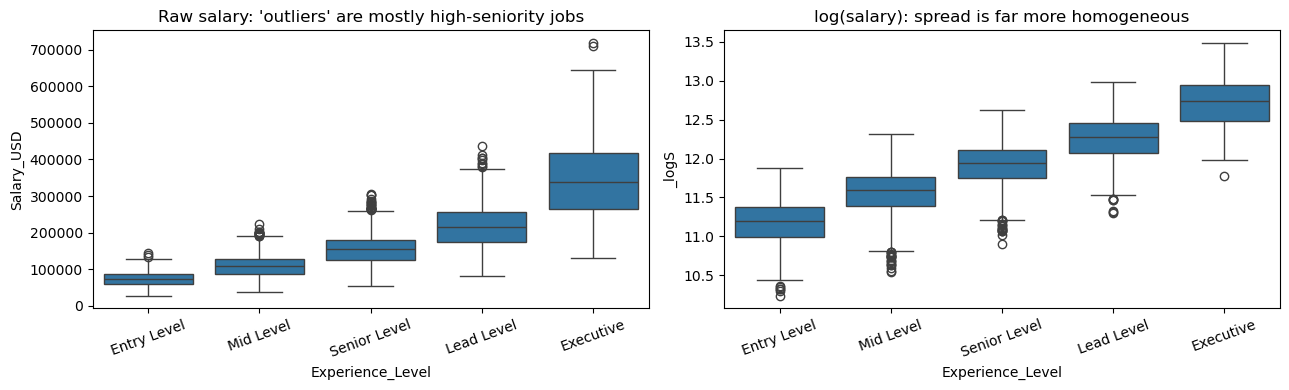

In [6]:
# 5.6 Outlier analysis on the target
# A global IQR rule would wrongly flag every Executive salary. Use a *robust z-score within each
# seniority group* on log-salary: z = 0.6745 * (x - median) / MAD, flag |z| > 3.5.
df["_logS"] = np.log(df.Salary_USD)

def robust_z(s):
    med = s.median(); mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad

df["_rz"] = df.groupby("Experience_Level")["_logS"].transform(robust_z)
q1, q3 = df.Salary_USD.quantile([.25, .75]); iqr = q3 - q1
global_iqr_out = ((df.Salary_USD > q3 + 1.5 * iqr) | (df.Salary_USD < q1 - 1.5 * iqr)).sum()
group_out = (df["_rz"].abs() > 3.5).sum()
print(f"Global IQR rule flags      : {global_iqr_out} rows ({global_iqr_out/len(df):.1%})")
print(f"Within-level robust-z flags: {group_out} rows ({group_out/len(df):.1%})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = ["Entry Level", "Mid Level", "Senior Level", "Lead Level", "Executive"]
sns.boxplot(data=df, x="Experience_Level", y="Salary_USD", order=order, ax=ax[0])
ax[0].set_title("Raw salary: 'outliers' are mostly high-seniority jobs"); ax[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=df, x="Experience_Level", y="_logS", order=order, ax=ax[1])
ax[1].set_title("log(salary): spread is far more homogeneous"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

**Decision on outliers:** high salaries are *legitimate* (they are Executives / Leads in expensive countries), not errors. Deleting them would bias the model against exactly the cases where benchmarking is most valuable. Instead of removing them we **model log-salary**, which tames the skew and stabilises the variance (shown in §8).

In [7]:
# 5.7 Skills column: parse the comma-separated string into a clean token list
df["Skills_List"] = df.Skills_Required.str.split(r"\s*,\s*")
all_skills = Counter(s for L in df.Skills_List for s in set(L))
print("Distinct skill tokens:", len(all_skills), "| empty tokens:", sum(1 for s in all_skills if s == ""))
print("Skills per posting:", df.Skills_List.str.len().describe()[["min", "mean", "max"]].round(2).to_dict())
print("Top 10:", all_skills.most_common(10))

# 5.8 Final cleaned frame: drop IDs / constants / dates / helper columns
DROP_NOISE = ["Record_Created", "Data_Source", "Posted_Date", "Application_Deadline",
              "_logS", "_rz", "Skills_List"]
data = df.drop(columns=DROP_NOISE).set_index("Job_ID")
print("\nCleaned shape:", data.shape)

Distinct skill tokens: 102 | empty tokens: 0
Skills per posting: {'min': 4.0, 'mean': 5.76, 'max': 6.0}
Top 10: [('Python', 4008), ('PyTorch', 1396), ('SQL', 981), ('Research', 868), ('AWS/GCP/Azure', 846), ('AWS/GCP', 752), ('Deep Learning', 718), ('C++', 689), ('Teaching', 614), ('Docker', 584)]

Cleaned shape: (5000, 32)


## 6. Target-leakage audit (critical)

*Leakage* = a feature that contains (or is computed from) the target. Such a feature makes validation scores look magical but it would not exist in production, where the salary is exactly the thing we are trying to determine.

Suspects: `Salary_Min`, `Salary_Max`, `Salary_Category`.

Salary_Min / Salary_USD : {'min': 0.7, 'mean': 0.801, 'max': 0.9}
Salary_Max / Salary_USD : {'min': 1.1, 'mean': 1.251, 'max': 1.4}
Correlation with target : Min = 0.9872 | Max = 0.9881

Salary_Category = fixed bins of the target:


,min,max,count
Salary_Category,,,
Low,27934.0,49877.0,68
Lower-Mid,50127.0,79957.0,493
Mid,80058.0,119988.0,1208
Upper-Mid,120130.0,179971.0,1736
High,180042.0,249690.0,951
Very High,250084.0,718357.0,544


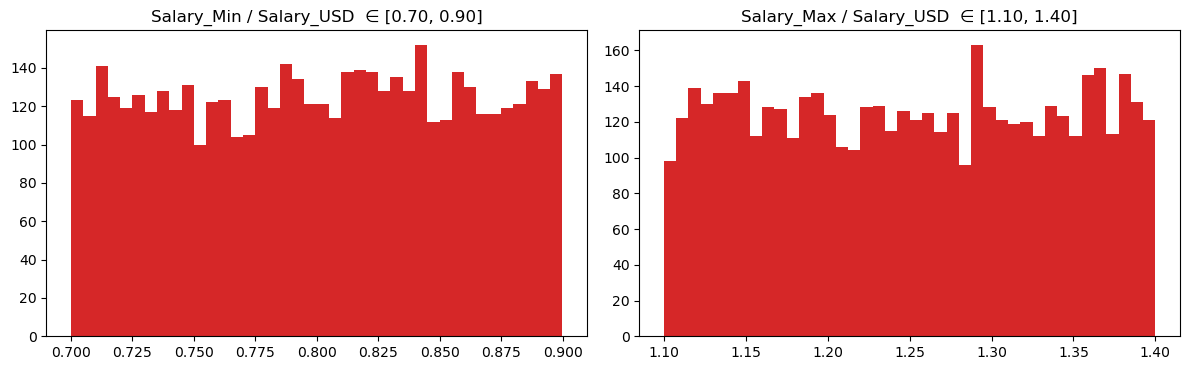

In [8]:
ratio_min = data.Salary_Min / data.Salary_USD
ratio_max = data.Salary_Max / data.Salary_USD
print("Salary_Min / Salary_USD :", ratio_min.describe()[["min", "mean", "max"]].round(3).to_dict())
print("Salary_Max / Salary_USD :", ratio_max.describe()[["min", "mean", "max"]].round(3).to_dict())
print("Correlation with target : Min =", round(data.Salary_Min.corr(data.Salary_USD), 4),
      "| Max =", round(data.Salary_Max.corr(data.Salary_USD), 4))
print("\nSalary_Category = fixed bins of the target:")
display(data.groupby("Salary_Category").Salary_USD.agg(["min", "max", "count"]).sort_values("min"))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(ratio_min, bins=40, color="tab:red"); ax[0].set_title("Salary_Min / Salary_USD  ∈ [0.70, 0.90]")
ax[1].hist(ratio_max, bins=40, color="tab:red"); ax[1].set_title("Salary_Max / Salary_USD  ∈ [1.10, 1.40]")
plt.tight_layout(); plt.show()

**Verdict.** $\text{Salary\_Min} = u_1\cdot\text{Salary}$ with $u_1\sim U(0.7,0.9)$ and $\text{Salary\_Max}=u_2\cdot\text{Salary}$ with $u_2\sim U(1.1,1.4)$; `Salary_Category` is a set of hard bins of the target. Together they let a model reconstruct the salary almost exactly. **All three are removed from the feature set.** In §15 we *quantify* how inflated the scores would have been.

A second, more subtle leakage family is **temporal availability**: some features only exist *after* a posting is live (`Competition_Level_Applicants`, `Hiring_Difficulty_Score`) or after someone is hired (`Job_Satisfaction_Score`, `Work_Life_Balance_Score`). If the model is meant to *set* a salary for a new posting, using them is unrealistic. We keep them as *candidates* but test them in the ablation study in §10 and exclude them from the deployable model if they add nothing.

In [9]:
LEAKY = ["Salary_Min", "Salary_Max", "Salary_Category"]
POST_POSTING = ["Competition_Level_Applicants", "Hiring_Difficulty_Score",
                "Job_Satisfaction_Score", "Work_Life_Balance_Score"]
TARGET = "Salary_USD"

leak_frame = data[LEAKY + [TARGET]].copy()       # kept ONLY for the leakage demo in §15
data = data.drop(columns=LEAKY)
print("Remaining columns:", data.shape[1] - 1, "features + target")

# Column groups used throughout
CAT_OHE = ["Experience_Level", "Education_Required", "Company_Size", "Continent", "AI_Specialization",
           "Required_Certifications", "Job_Type", "Equity_Offered", "Work_From_Home_Available"]
CAT_TE = ["Country", "Job_Title", "Industry", "Company"]          # high-cardinality -> target encoding
NUM_COLS = [c for c in data.columns if c not in CAT_OHE + CAT_TE + ["Skills_Required", TARGET]]
print("Numeric features:", NUM_COLS)

Remaining columns: 28 features + target
Numeric features: ['Years_of_Experience', 'Bonus_Pct', 'Benefits_Value_USD', 'Job_Openings', 'Competition_Level_Applicants', 'Hiring_Difficulty_Score', 'Remote_Work_Pct', 'Job_Satisfaction_Score', 'Work_Life_Balance_Score', 'AI_Investment_Company_Millions', 'Company_AI_Maturity_Score', 'Job_Growth_Projection_Pct', 'Automation_Risk_Pct', 'Gender_Diversity_Pct_Female']


## 7. Train / test split — the test set goes into a vault

We split **now**, before any EDA or fitting, so that nothing we learn (distribution shapes, encodings, selected features) is contaminated by the test rows. Stratifying on salary deciles keeps the target distribution identical in both parts.

In [10]:
from sklearn.model_selection import train_test_split

y_all = np.log(data[TARGET])                       # model target: ln(Salary)
strata = pd.qcut(y_all, 10, labels=False)
train_idx, test_idx = train_test_split(data.index, test_size=0.20, random_state=SEED, stratify=strata)

X_train = data.loc[train_idx].drop(columns=TARGET); y_train = y_all.loc[train_idx]
X_test = data.loc[test_idx].drop(columns=TARGET);   y_test = y_all.loc[test_idx]
train_df = data.loc[train_idx].copy(); train_df["logSalary"] = y_train      # used for EDA ONLY

print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print("Mean ln(salary) train / test:", round(y_train.mean(), 4), "/", round(y_test.mean(), 4))
print("Index overlap:", len(set(X_train.index) & set(X_test.index)))

Train: (4000, 28)   Test: (1000, 28)
Mean ln(salary) train / test: 11.8629 / 11.8589
Index overlap: 0


## 8. Exploratory data analysis & visualisation
**All EDA uses the training set only.**

### 8.1 The target: why we model $\ln(\text{Salary})$

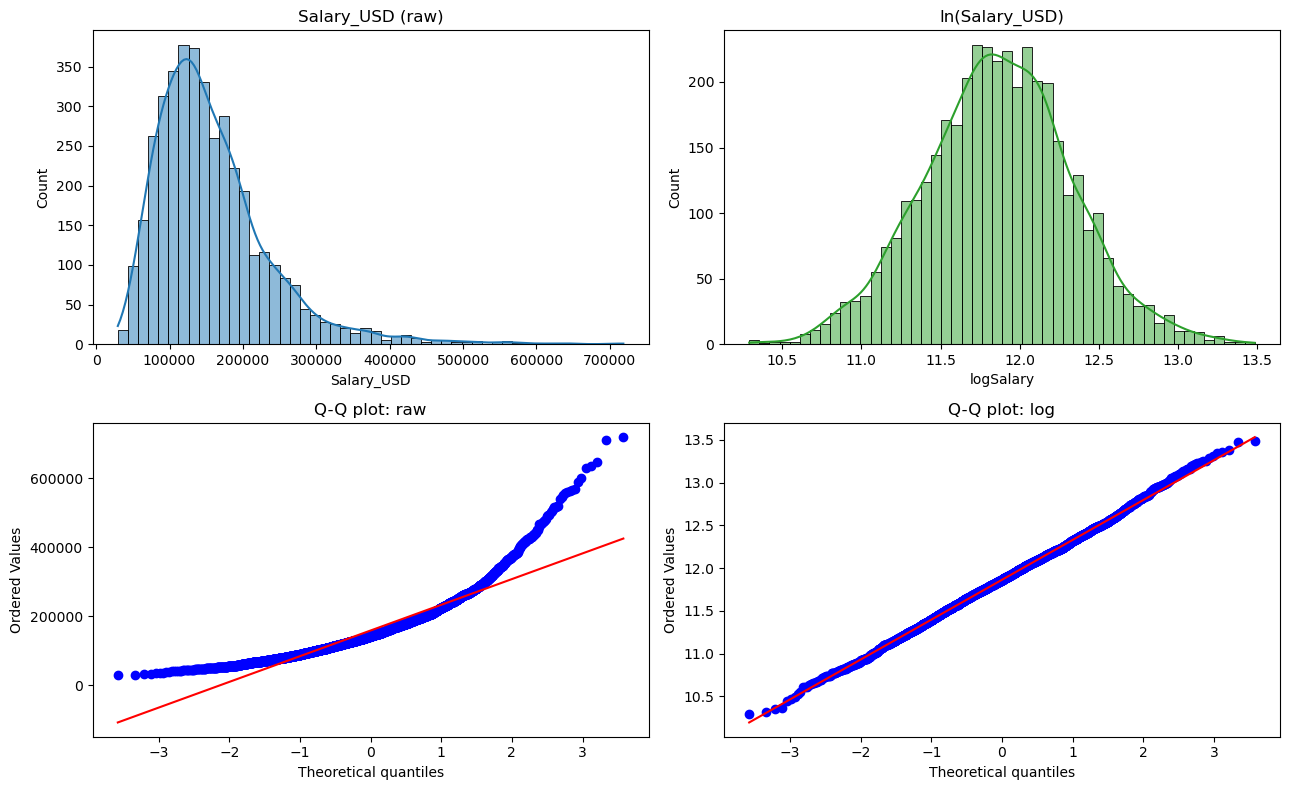

,skewness,excess kurtosis,D'Agostino K² p-value
raw,1.7468,5.2542,0.0000
ln,0.0342,0.1115,0.2446


Box–Cox MLE lambda = -0.023  (λ≈0 ⇔ log transform is the optimal power transform)


In [11]:
s_raw = train_df[TARGET]; s_log = train_df["logSalary"]

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(s_raw, bins=50, kde=True, ax=ax[0, 0], color="tab:blue"); ax[0, 0].set_title("Salary_USD (raw)")
sns.histplot(s_log, bins=50, kde=True, ax=ax[0, 1], color="tab:green"); ax[0, 1].set_title("ln(Salary_USD)")
stats.probplot(s_raw, dist="norm", plot=ax[1, 0]); ax[1, 0].set_title("Q-Q plot: raw")
stats.probplot(s_log, dist="norm", plot=ax[1, 1]); ax[1, 1].set_title("Q-Q plot: log")
plt.tight_layout(); plt.show()

lam = stats.boxcox_normmax(s_raw, method="mle")
summary = pd.DataFrame({
    "skewness": [stats.skew(s_raw), stats.skew(s_log)],
    "excess kurtosis": [stats.kurtosis(s_raw), stats.kurtosis(s_log)],
    "D'Agostino K² p-value": [stats.normaltest(s_raw)[1], stats.normaltest(s_log)[1]],
}, index=["raw", "ln"]).round(4)
display(summary)
print(f"Box–Cox MLE lambda = {lam:.3f}  (λ≈0 ⇔ log transform is the optimal power transform)")

**Why the log?** Salaries behave *multiplicatively*: seniority and geography scale pay by a factor rather than adding a fixed amount. If
$$\text{Salary} = B \cdot \underbrace{m_{\text{level}}}_{\text{seniority}}\cdot \underbrace{m_{\text{country}}}_{\text{geography}}\cdot \varepsilon$$
then
$$\ln \text{Salary} = \ln B + \ln m_{\text{level}} + \ln m_{\text{country}} + \ln\varepsilon ,$$
which is **additive** — ideal for linear models, and it equalises the variance (heteroscedasticity) we saw in the boxplots. The Box–Cox optimum $\lambda\approx 0$ confirms this empirically, and skewness collapses to ≈ 0. A coefficient $\beta$ on the log scale translates to a percentage effect $e^{\beta}-1$.

### 8.2 Categorical drivers of salary

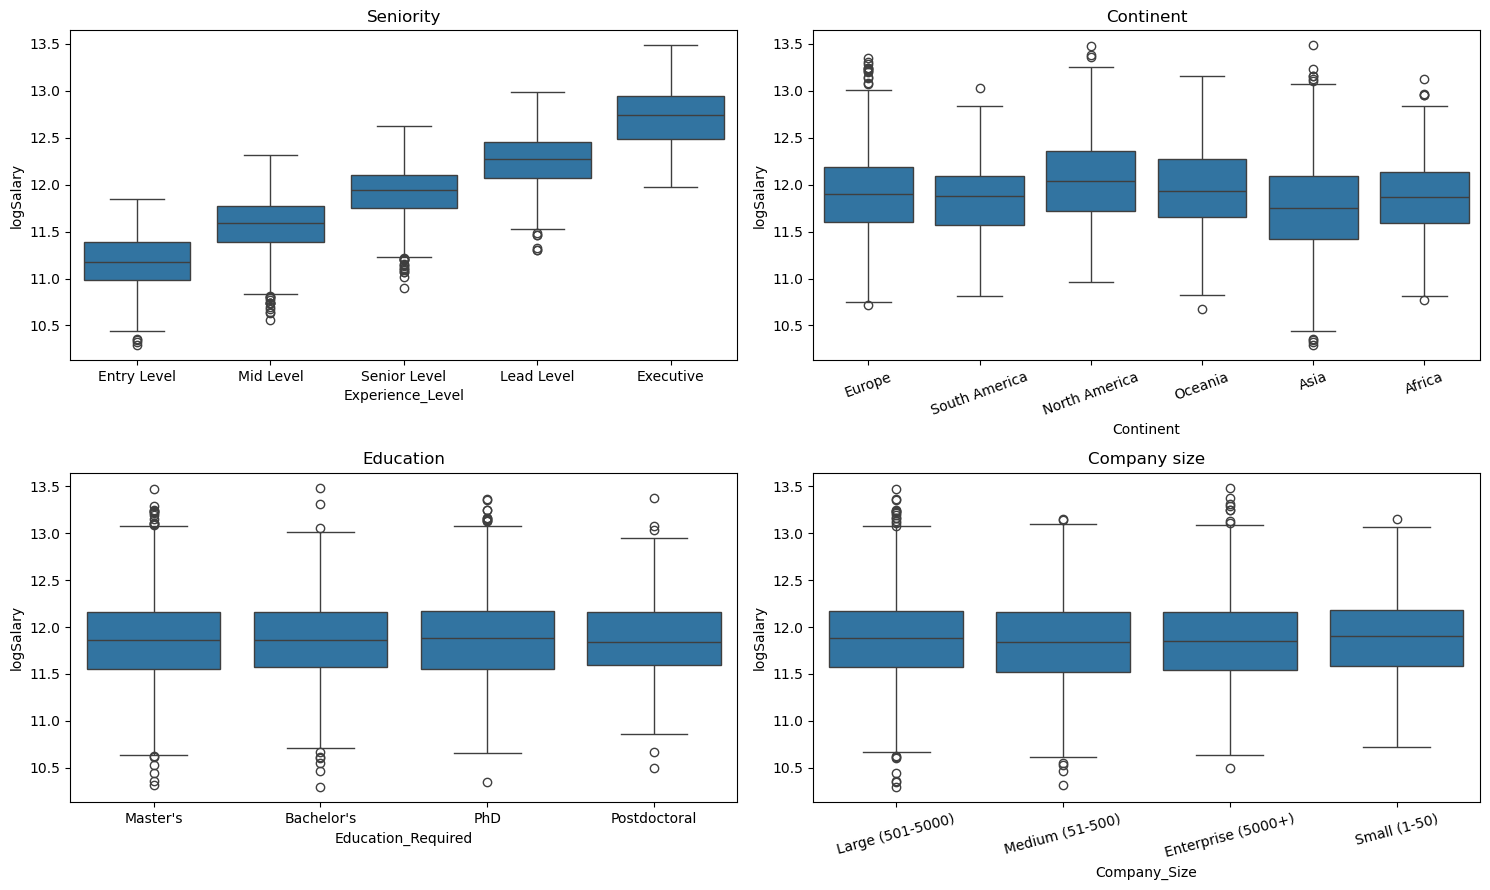

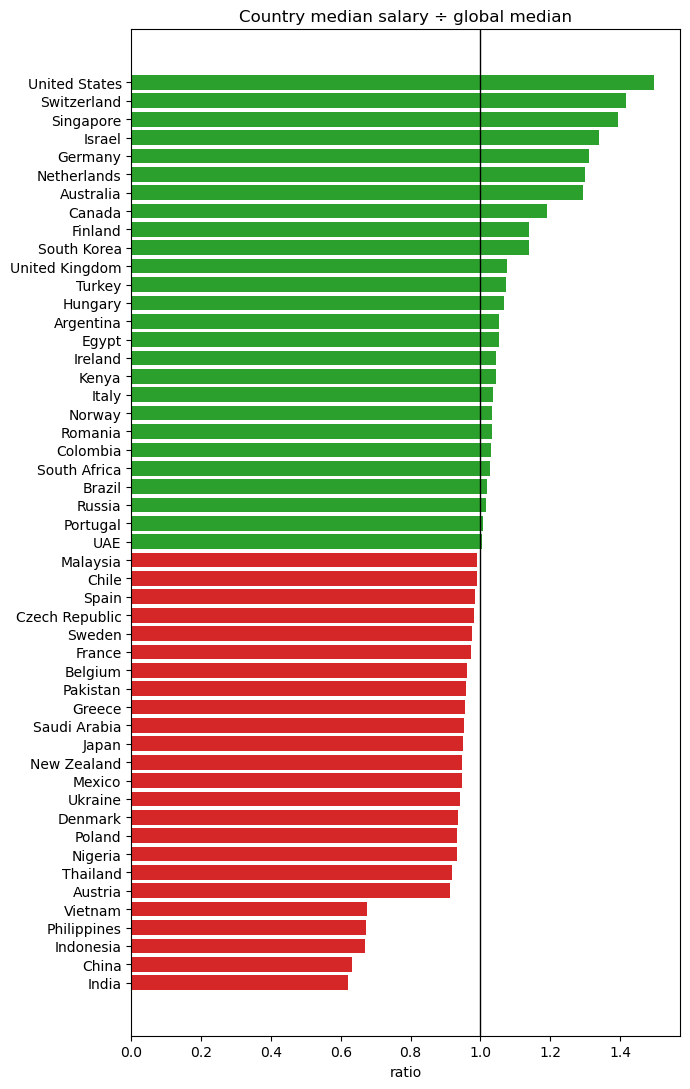

Spread between the cheapest and priciest country: ×2.42


In [12]:
order = ["Entry Level", "Mid Level", "Senior Level", "Lead Level", "Executive"]
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
sns.boxplot(data=train_df, x="Experience_Level", y="logSalary", order=order, ax=ax[0, 0]); ax[0, 0].set_title("Seniority")
sns.boxplot(data=train_df, x="Continent", y="logSalary", ax=ax[0, 1]); ax[0, 1].set_title("Continent"); ax[0, 1].tick_params(axis="x", rotation=20)
sns.boxplot(data=train_df, x="Education_Required", y="logSalary", ax=ax[1, 0]); ax[1, 0].set_title("Education")
sns.boxplot(data=train_df, x="Company_Size", y="logSalary", ax=ax[1, 1]); ax[1, 1].set_title("Company size"); ax[1, 1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

# Country premium = median salary relative to the global median
ctry = (train_df.groupby("Country")[TARGET].median() / train_df[TARGET].median()).sort_values()
fig, ax = plt.subplots(figsize=(7, 11))
ax.barh(ctry.index, ctry.values, color=np.where(ctry.values >= 1, "tab:green", "tab:red"))
ax.axvline(1, color="k", lw=1); ax.set_title("Country median salary ÷ global median"); ax.set_xlabel("ratio")
plt.tight_layout(); plt.show()
print(f"Spread between the cheapest and priciest country: ×{ctry.max()/ctry.min():.2f}")

### 8.3 Role, industry and specialisation

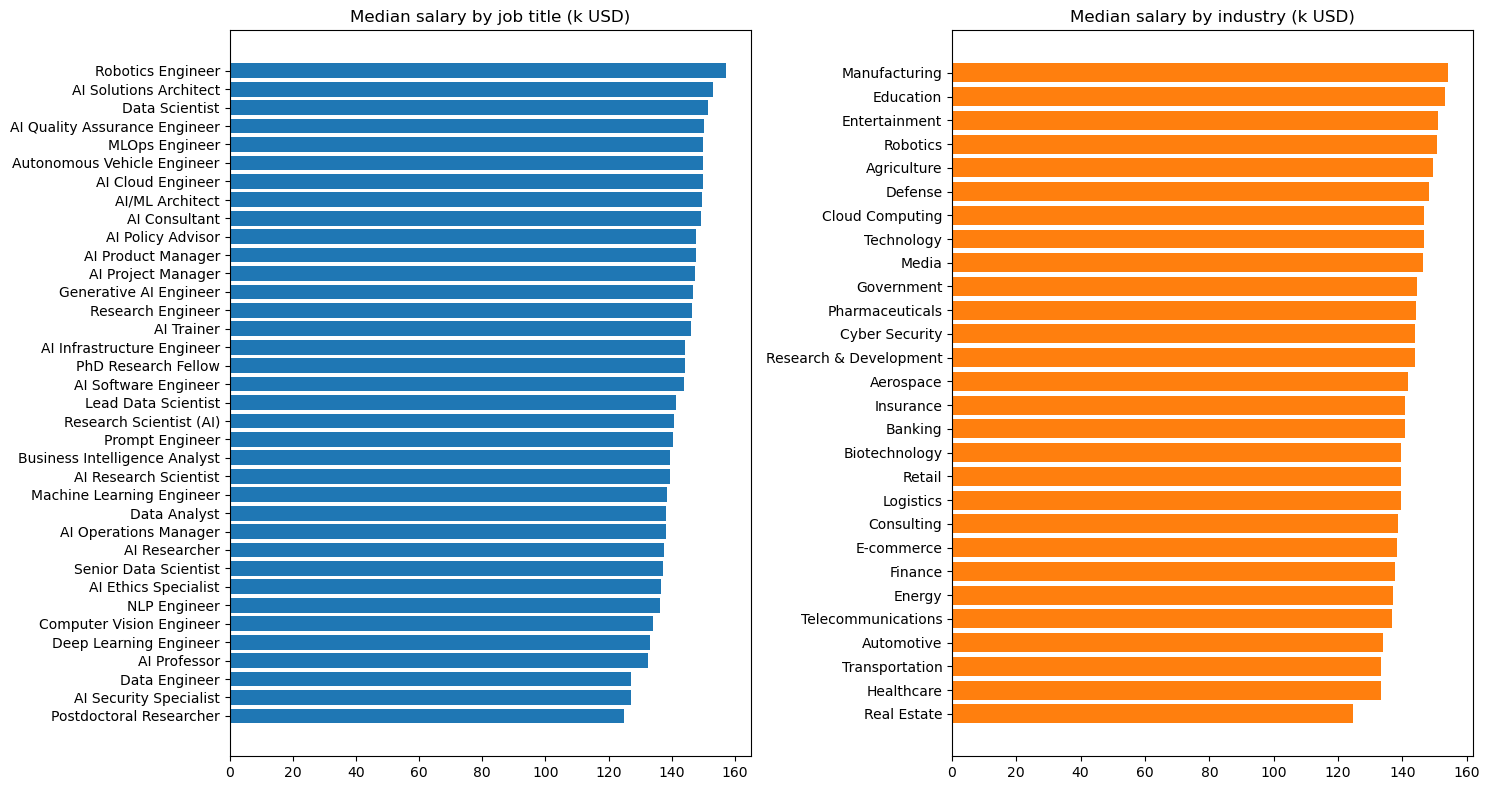

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 8))
jt = train_df.groupby("Job_Title")[TARGET].median().sort_values()
ax[0].barh(jt.index, jt.values / 1e3, color="tab:blue"); ax[0].set_title("Median salary by job title (k USD)")
ind = train_df.groupby("Industry")[TARGET].median().sort_values()
ax[1].barh(ind.index, ind.values / 1e3, color="tab:orange"); ax[1].set_title("Median salary by industry (k USD)")
plt.tight_layout(); plt.show()

**Visual impression:** medians vary a little by title and industry, but with ~110 rows per title and ~140 per industry, chance alone produces such differences. The formal tests below settle it.

### 8.4 Statistical tests: *how much* of the variance does each categorical explain?
Visual differences can be noise. For each categorical variable with $k$ groups and $n$ rows we run a **Kruskal–Wallis $H$ test** (non-parametric ANOVA, no normality assumption) and compute the effect size
$$\eta^2_H=\frac{H-k+1}{n-k}\in[0,1],$$
the (approximate) share of variance in $\ln$-salary explained by group membership.

,feature,k_groups,H,p_value,eta2,significant_5%
0,Experience_Level,5,2594.7454,0.0000,0.6485,True
1,Country,50,550.4679,0.0000,0.1270,True
2,Continent,6,107.5783,0.0000,0.0257,True
3,Required_Certifications,6,11.1192,0.0491,0.0015,True
4,Job_Type,4,6.2288,0.1010,0.0008,False
5,Company_Size,4,6.1279,0.1056,0.0008,False
6,Job_Title,36,38.0186,0.3335,0.0008,False
7,AI_Specialization,8,7.7448,0.3556,0.0002,False
8,Education_Required,4,0.7734,0.8558,0.0000,False
9,Work_From_Home_Available,2,0.0319,0.8583,0.0000,False


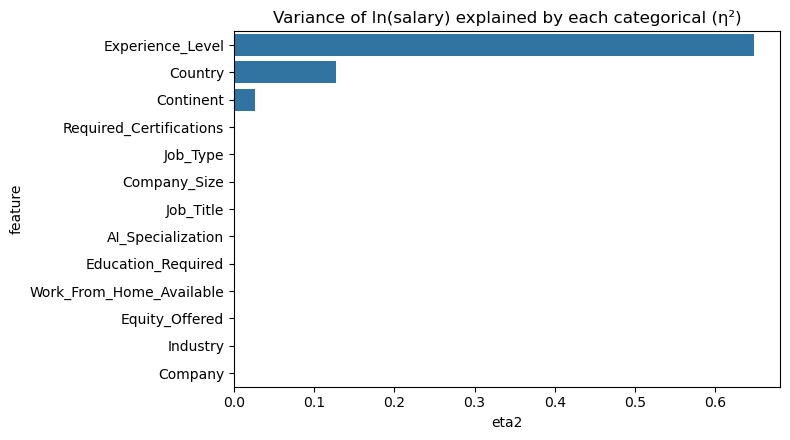

In [14]:
rows = []
for col in CAT_OHE + CAT_TE:
    groups = [g.values for _, g in train_df.groupby(col)["logSalary"]]
    H, p = stats.kruskal(*groups)
    k, n = len(groups), len(train_df)
    rows.append((col, k, H, p, max((H - k + 1) / (n - k), 0)))
kw = pd.DataFrame(rows, columns=["feature", "k_groups", "H", "p_value", "eta2"]).sort_values("eta2", ascending=False)
kw["significant_5%"] = kw.p_value < 0.05
display(kw.round(4).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=kw, x="eta2", y="feature", color="tab:blue", ax=ax)
ax.set_title("Variance of ln(salary) explained by each categorical (η²)"); plt.tight_layout(); plt.show()

**Results.** Only three variables carry statistically detectable signal: **`Experience_Level` (η² ≈ 0.65)**, **`Country` (η² ≈ 0.13)** and `Continent` (η² ≈ 0.03, which is just a coarser version of Country). `Required_Certifications` is borderline (p ≈ 0.049, η² ≈ 0.0015 — negligible, and not robust to multiple testing across 13 tests). **Job title, industry, specialisation, education, company size, job type, equity, remote availability and company: no detectable effect** (all p > 0.09). This *refutes* hypothesis H3 — in this dataset role and industry do not move pay once the sample noise is accounted for.

### 8.5 Numeric features: correlation, mutual information, multicollinearity

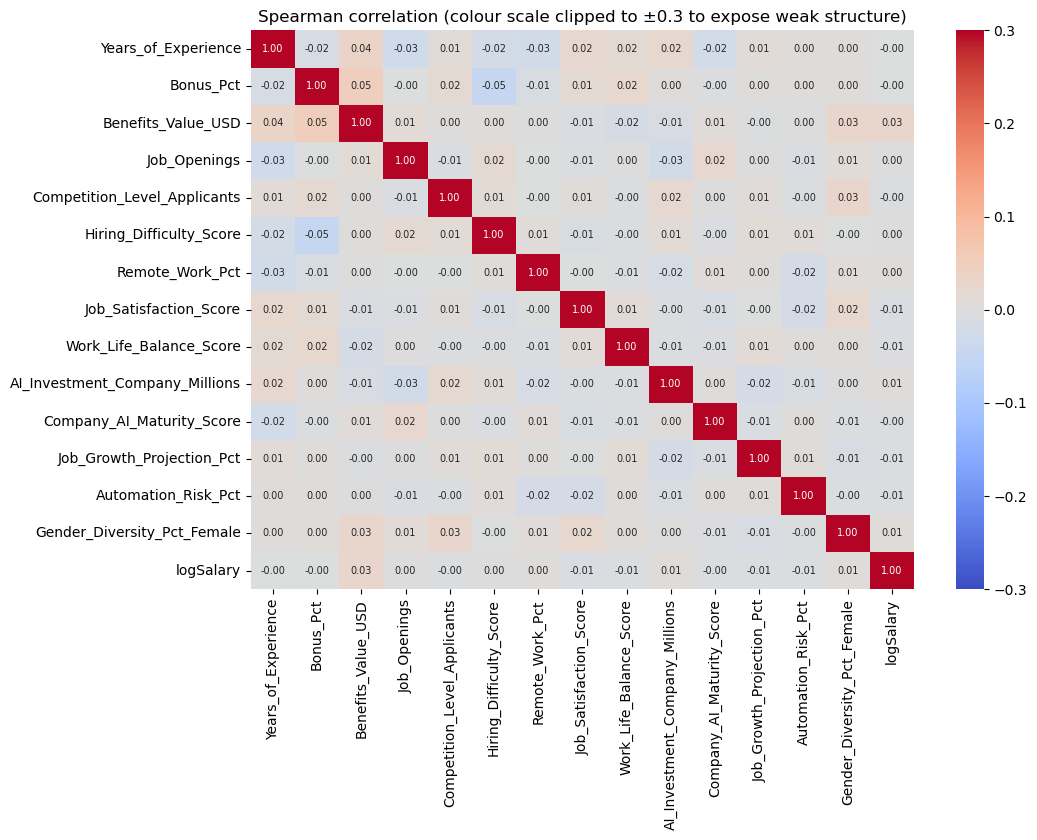

,rho,p,significant_5%
Benefits_Value_USD,0.0261,0.0986,False
Job_Satisfaction_Score,-0.0092,0.5624,False
AI_Investment_Company_Millions,0.0068,0.6659,False
Job_Growth_Projection_Pct,-0.0062,0.6966,False
Gender_Diversity_Pct_Female,0.0054,0.7305,False
Automation_Risk_Pct,-0.0054,0.7350,False
Work_Life_Balance_Score,-0.0052,0.7442,False
Company_AI_Maturity_Score,-0.0042,0.7897,False
Competition_Level_Applicants,-0.0037,0.8130,False
Remote_Work_Pct,0.0027,0.8658,False


In [15]:
num_train = train_df[NUM_COLS + ["logSalary"]]

# Spearman (rank) correlation is robust to non-linear monotone relationships
corr = num_train.corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-.3, vmax=.3, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation (colour scale clipped to ±0.3 to expose weak structure)")
plt.tight_layout(); plt.show()

sp = pd.DataFrame({r: stats.spearmanr(num_train[r], num_train.logSalary) for r in NUM_COLS}, index=["rho", "p"]).T
sp["significant_5%"] = sp.p < 0.05
display(sp.sort_values("rho", key=abs, ascending=False).round(4))

**Reading the heat-map:** every numeric feature has $|\rho|<0.03$ with the target and with one another — numeric columns are essentially *independent noise* relative to salary. Strikingly, **`Years_of_Experience` does not correlate with salary** even though common sense says it should; the seniority signal lives in the categorical `Experience_Level`.

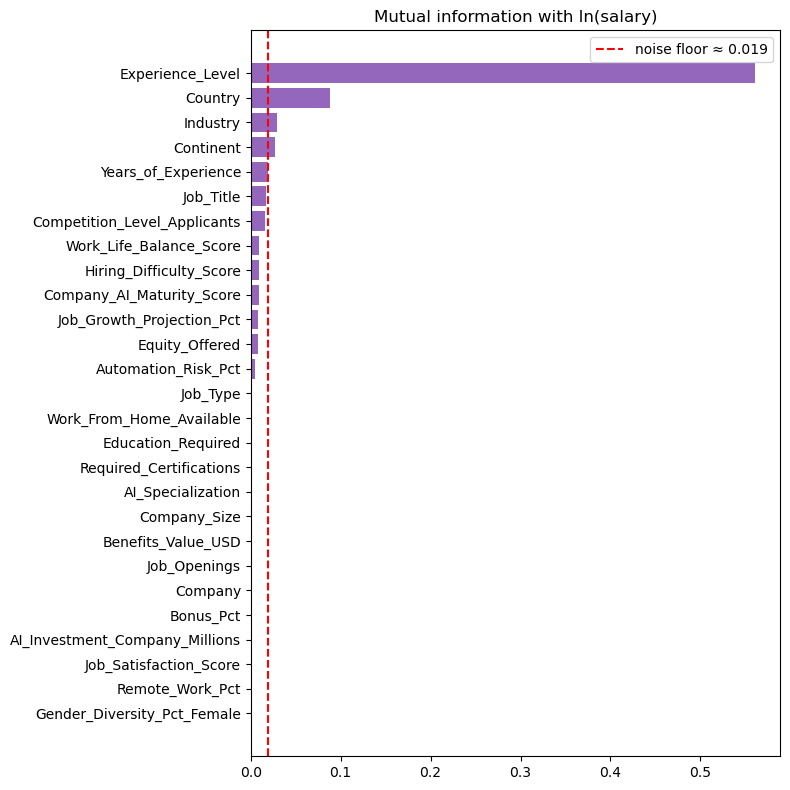

Features above the noise floor: ['Experience_Level', 'Country', 'Industry', 'Continent']


In [16]:
# Mutual information captures non-linear dependence that correlation misses.
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import OrdinalEncoder

Xmi = train_df[CAT_OHE + CAT_TE + NUM_COLS].copy()
Xmi[CAT_OHE + CAT_TE] = OrdinalEncoder().fit_transform(Xmi[CAT_OHE + CAT_TE])
mask = [c in CAT_OHE + CAT_TE for c in Xmi.columns]
mi = mutual_info_regression(Xmi, train_df.logSalary, discrete_features=mask, random_state=SEED, n_neighbors=5)
mi = pd.Series(mi, index=Xmi.columns).sort_values(ascending=False)

# MI of a feature with a *shuffled* target gives the "noise floor" of the estimator
rng = np.random.default_rng(SEED)
floor = np.mean([mutual_info_regression(Xmi, rng.permutation(train_df.logSalary.values), discrete_features=mask,
                                        random_state=i, n_neighbors=5).max() for i in range(3)])
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(mi.index[::-1], mi.values[::-1], color="tab:purple"); ax.axvline(floor, color="red", ls="--", label=f"noise floor ≈ {floor:.3f}")
ax.set_title("Mutual information with ln(salary)"); ax.legend(); plt.tight_layout(); plt.show()
print("Features above the noise floor:", list(mi[mi > floor].index))

**Caution — a filter can mislead.** Mutual information flags `Industry` as informative, yet the Kruskal–Wallis test (p ≈ 0.80) and, later, permutation importance (≈ 0) say it is not. MI estimators are biased upward for discrete variables with many levels (28 industries), which is exactly why we never rely on one filter and use several independent lines of evidence in §10.

In [17]:
# Multicollinearity: Variance Inflation Factor  VIF_j = 1 / (1 - R_j^2)
from statsmodels.stats.outliers_influence import variance_inflation_factor
Z = (num_train[NUM_COLS] - num_train[NUM_COLS].mean()) / num_train[NUM_COLS].std()
Z.insert(0, "const", 1.0)
vif = pd.Series([variance_inflation_factor(Z.values, i) for i in range(1, Z.shape[1])], index=NUM_COLS).sort_values(ascending=False)
display(vif.round(3).to_frame("VIF"))
print("Max VIF =", round(vif.max(), 3), "(rule of thumb: >5 problematic, >10 severe)")

,VIF
Bonus_Pct,1.007
Years_of_Experience,1.006
Benefits_Value_USD,1.006
Hiring_Difficulty_Score,1.004
Job_Openings,1.003
AI_Investment_Company_Millions,1.003
Gender_Diversity_Pct_Female,1.002
Job_Satisfaction_Score,1.002
Competition_Level_Applicants,1.002
Remote_Work_Pct,1.002


Max VIF = 1.007 (rule of thumb: >5 problematic, >10 severe)


### 8.6 Interactions: is salary really *multiplicative* in seniority × geography?
If the multiplicative model of §8.1 is right, the log-scale effects of seniority and continent are **additive**, i.e. the interaction term in a two-way ANOVA should be insignificant.

   df_resid       ssr  df_diff  ss_diff       F  Pr(>F)
0    3990.0  268.9361      0.0      NaN     NaN     NaN
1    3970.0  267.6629     20.0   1.2731  0.9442  0.5295

R² additive = 0.6906   R² with interaction = 0.6921


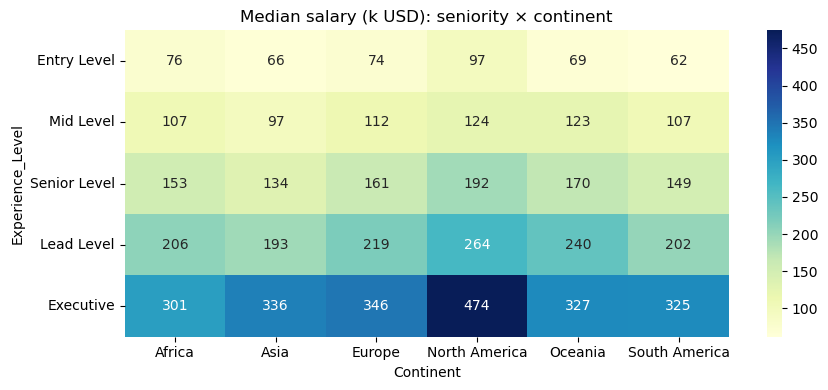

In [18]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

m_add = smf.ols("logSalary ~ C(Experience_Level) + C(Continent)", data=train_df).fit()
m_int = smf.ols("logSalary ~ C(Experience_Level) * C(Continent)", data=train_df).fit()
print(anova_lm(m_add, m_int).round(4))
print(f"\nR² additive = {m_add.rsquared:.4f}   R² with interaction = {m_int.rsquared:.4f}")

piv = train_df.pivot_table(index="Experience_Level", columns="Continent", values=TARGET, aggfunc="median").loc[order]
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(piv / 1e3, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax); ax.set_title("Median salary (k USD): seniority × continent")
plt.tight_layout(); plt.show()

The interaction adds nothing (F-test p-value is large; $R^2$ barely moves) → **the log-additive structure holds**. Practical consequence: a regularised *linear* model on $\ln(\text{salary})$ should already be near-optimal, and complex tree ensembles have little additional structure to find. We will test this claim directly in §12.

### 8.7 Skills: which skills carry a *real* premium?
Raw skill premiums are **confounded** — "Teaching" is common in professor roles, so it looks poorly/highly paid only because of the *job*. We therefore first remove the effect of seniority, country and job title with an OLS fit, and test the **residuals**:
$$e_i=\ln S_i-\widehat{\ln S_i}\big(\text{level},\text{country},\text{title}\big)$$
For each of the 30 most common skills we run a Welch $t$-test of residuals (skill present vs. absent), and control the false-discovery rate across the 30 simultaneous tests with the **Benjamini–Hochberg** procedure.

In [19]:
from statsmodels.stats.multitest import multipletests

base = smf.ols("logSalary ~ C(Experience_Level) + C(Country) + C(Job_Title)", data=train_df).fit()
resid = base.resid
print(f"Seniority+country+title explain R² = {base.rsquared:.3f} of ln(salary)")

skills_tr = train_df.Skills_Required.str.split(r"\s*,\s*")
top_skills = [s for s, _ in Counter(s for L in skills_tr for s in set(L)).most_common(30)]
res = []
for s in top_skills:
    has = skills_tr.apply(lambda L: s in L).values
    t, p = stats.ttest_ind(resid[has], resid[~has], equal_var=False)
    res.append((s, has.sum(), resid[has].mean() - resid[~has].mean(), t, p))
sk = pd.DataFrame(res, columns=["skill", "n_with", "delta_ln", "t", "p"])
sk["p_BH"] = multipletests(sk.p, method="fdr_bh")[1]
sk["premium_%"] = (np.exp(sk.delta_ln) - 1) * 100
display(sk.sort_values("p_BH").head(10).round(4))
print("Skills significant after FDR control (q<0.05):", int((sk.p_BH < .05).sum()), "of", len(sk))

Seniority+country+title explain R² = 0.796 of ln(salary)


,skill,n_with,delta_ln,t,p,p_BH,premium_%
0,Python,3213,0.0008,0.0916,0.9271,1.0,0.0751
1,PyTorch,1106,0.0009,0.1231,0.9020,1.0,0.0919
2,SQL,796,0.0022,0.2555,0.7984,1.0,0.2162
3,Research,692,0.0000,0.0000,1.0000,1.0,0.0000
4,AWS/GCP/Azure,688,-0.0000,-0.0000,1.0000,1.0,-0.0000
5,AWS/GCP,608,0.0013,0.1347,0.8929,1.0,0.1281
6,Deep Learning,562,0.0000,0.0000,1.0000,1.0,0.0000
7,C++,560,-0.0029,-0.3049,0.7606,1.0,-0.2894
8,Teaching,485,0.0000,0.0000,1.0000,1.0,0.0000
9,AI/ML,467,-0.0000,-0.0000,1.0000,1.0,-0.0000


Skills significant after FDR control (q<0.05): 0 of 30


### 8.8 EDA conclusions
| Hypothesis | Verdict |
|---|---|
| H1 seniority dominant |  Strongest effect by far (see η²) |
| H2 geography |  Second driver; cheapest-to-priciest country spread ≈ ×2.4 |
| H3 role/industry |  Refuted — no detectable effect (p = 0.33 title, p = 0.80 industry) |
| H4 numeric company/soft metrics |  Confirmed ≈ pure noise (|ρ|<0.03, MI below noise floor) |
| H5 leaky columns |  Confirmed & removed |

Additional insights: log-additive structure (interaction p = 0.53); `Years_of_Experience` has no relationship with salary at all; **none of the 30 most common skills carries a significant premium** (0/30 after FDR control); numeric features are mutually independent (VIF ≈ 1.0). In short: **two variables — seniority and country — explain essentially everything that is explainable.**

## 9. Feature engineering (with the maths)

All transformations are implemented as scikit-learn transformers so they are **fitted on the training fold only**.

### 9.1 Mathematical toolbox

**(a) Ordinal encoding** for naturally ordered variables (`Experience_Level`, `Education_Required`, `Company_Size`): $x\in\{0,1,\dots,K-1\}$, preserving order and giving linear models a single, interpretable slope.

**(b) Power transforms of `Years_of_Experience`** $x$: $\log(1+x)$ (diminishing returns), $\sqrt{x}$ (milder compression). We keep them only if they help (§10).

**(c) Empirical-Bayes (shrinkage) target encoding** for high-cardinality categoricals (Country: 50, Job_Title: 36, Industry: 28, Company: 60). One-hot encoding would add >170 sparse columns. Instead each level $c$ is replaced by a *shrunk* mean of the target:
$$\hat\mu_c=\lambda_c\,\bar y_c+(1-\lambda_c)\,\bar y,\qquad \lambda_c=\frac{n_c}{n_c+m}$$
where $\bar y_c$ is the level mean, $\bar y$ the global mean, $n_c$ the level count and $m$ the smoothing strength (the ratio of within-level to between-level variance, estimated automatically by `smooth="auto"`). Rare levels are pulled toward the global mean, which controls variance. Crucially, scikit-learn's `TargetEncoder` is **cross-fitted** — a row's encoding is computed from folds that do *not* contain that row — so the target never leaks into the training features.

**(d) Skill features** (parsed from `Skills_Required`):
* `skill_count` = number of skills;
* *multi-hot* indicators for skills present in ≥ 2 % of the training rows;
* **IDF rarity score**: $\text{rarity}_i=\sum_{s\in \text{skills}_i}\ln\!\frac{N}{df_s}$ where $df_s$ is the number of training postings containing skill $s$ (information-theoretic "surprisal" of a skill; a posting asking for rare skills scores higher).

**(e) Ratio / interaction features**: `applicants_per_opening` $=\frac{\text{applicants}}{\text{openings}}$ (market tightness), and `inv_x_maturity` $=\ln(1+\text{AI investment})\times\text{maturity}$ (a company that invests a lot *and* is mature).

**(f) Log transforms of right-skewed numerics.** Skewness is checked first — we only claim a benefit where it exists:

In [20]:
skew_tbl = train_df[NUM_COLS].apply(stats.skew).sort_values(key=abs, ascending=False).to_frame("skewness")
skew_tbl["distribution"] = np.where(skew_tbl.skewness.abs() < .3, "≈ symmetric / uniform", "skewed")
display(skew_tbl.round(3))

,skewness,distribution
Years_of_Experience,0.574,skewed
Remote_Work_Pct,-0.343,skewed
Job_Openings,0.333,skewed
Competition_Level_Applicants,-0.029,≈ symmetric / uniform
Gender_Diversity_Pct_Female,-0.025,≈ symmetric / uniform
Bonus_Pct,0.024,≈ symmetric / uniform
Work_Life_Balance_Score,0.018,≈ symmetric / uniform
Hiring_Difficulty_Score,-0.018,≈ symmetric / uniform
Job_Growth_Projection_Pct,0.016,≈ symmetric / uniform
AI_Investment_Company_Millions,-0.016,≈ symmetric / uniform


11 of the 14 numerics are essentially symmetric (the generating process looks uniform). Three bounded, integer-like columns are mildly skewed (`Years_of_Experience` 0.57, `Remote_Work_Pct` −0.34, `Job_Openings` 0.33) — nothing a log would dramatically "normalise". The transforms are kept as *candidates*; the permutation-importance study in §10 decides whether any survives.

In [21]:
# Do power transforms of Years_of_Experience carry signal *within* seniority levels?
# (Compare each transform's correlation with the residual of ln(salary) after removing seniority + country.)
r_exp = smf.ols("logSalary ~ C(Experience_Level) + C(Country)", data=train_df).fit().resid
x = train_df.Years_of_Experience
cand = {"x": x, "log(1+x)": np.log1p(x), "sqrt(x)": np.sqrt(x), "x^2": x ** 2}
tab = pd.DataFrame({k: [stats.pearsonr(v, r_exp)[0], stats.pearsonr(v, r_exp)[1]] for k, v in cand.items()},
                   index=["pearson_r", "p_value"]).T
display(tab.round(4))
print("→ None of the transforms of Years_of_Experience explains residual salary, so no transform can rescue it.")

,pearson_r,p_value
x,0.0201,0.2028
log(1+x),0.0143,0.3668
sqrt(x),0.0153,0.3328
x^2,0.0212,0.1802


→ None of the transforms of Years_of_Experience explains residual salary, so no transform can rescue it.


In [22]:
from sklearn.base import BaseEstimator, TransformerMixin

class JobFeatureEngineer(BaseEstimator, TransformerMixin):
    """
    Stateless + stateful feature engineering for the AI-jobs data.
    fit() learns ONLY from the training fold: skill document-frequencies and skill vocabulary.
    transform() returns the original columns plus engineered columns (a DataFrame).
    """
    EXP_ORDER = ["Entry Level", "Mid Level", "Senior Level", "Lead Level", "Executive"]
    EDU_ORDER = ["Bachelor's", "Master's", "PhD", "Postdoctoral"]
    SIZE_ORDER = ["Small (1-50)", "Medium (51-500)", "Large (501-5000)", "Enterprise (5000+)"]

    def __init__(self, min_skill_share=0.02):
        self.min_skill_share = min_skill_share

    @staticmethod
    def _split(s):
        return s.str.split(r"\s*,\s*")

    def fit(self, X, y=None):
        skills = self._split(X["Skills_Required"])
        self.n_docs_ = len(X)
        self.df_ = Counter(s for L in skills for s in set(L))                         # document frequency
        self.vocab_ = sorted(s for s, c in self.df_.items() if c / self.n_docs_ >= self.min_skill_share)
        return self

    def transform(self, X):
        X = X.copy()
        # (a) ordinal encodings (unknown level -> -1)
        X["exp_ord"] = X["Experience_Level"].map({v: i for i, v in enumerate(self.EXP_ORDER)}).fillna(-1)
        X["edu_ord"] = X["Education_Required"].map({v: i for i, v in enumerate(self.EDU_ORDER)}).fillna(-1)
        X["size_ord"] = X["Company_Size"].map({v: i for i, v in enumerate(self.SIZE_ORDER)}).fillna(-1)
        # (b) power transforms
        X["yoe_log1p"] = np.log1p(X["Years_of_Experience"])
        X["yoe_sqrt"] = np.sqrt(X["Years_of_Experience"])
        # (f) log transforms
        X["benefits_log"] = np.log(X["Benefits_Value_USD"])
        X["applicants_log"] = np.log(X["Competition_Level_Applicants"])
        X["inv_log"] = np.log1p(X["AI_Investment_Company_Millions"])
        # (e) ratios / interactions
        X["applicants_per_opening"] = X["Competition_Level_Applicants"] / X["Job_Openings"].clip(lower=1)
        X["inv_x_maturity"] = X["inv_log"] * X["Company_AI_Maturity_Score"]
        # (d) skills
        skills = self._split(X["Skills_Required"])
        X["skill_count"] = skills.str.len()
        X["skill_rarity"] = skills.apply(lambda L: sum(math.log(self.n_docs_ / self.df_.get(s, 1)) for s in L))
        hot = pd.DataFrame({f"sk__{re.sub(r'[^0-9A-Za-z]+', '_', s)}": skills.apply(lambda L, s=s: int(s in L))
                            for s in self.vocab_}, index=X.index)
        return pd.concat([X, hot], axis=1)

fe_demo = JobFeatureEngineer().fit(X_train)
eng = fe_demo.transform(X_train)
new_cols = [c for c in eng.columns if c not in X_train.columns]
print(f"{len(new_cols)} engineered columns, e.g.:", new_cols[:12], "...")
print(f"Skill vocabulary (≥2% of postings): {len(fe_demo.vocab_)} skills")
eng[["exp_ord", "yoe_log1p", "skill_count", "skill_rarity", "applicants_per_opening", "inv_x_maturity"]].describe().round(2)

107 engineered columns, e.g.: ['exp_ord', 'edu_ord', 'size_ord', 'yoe_log1p', 'yoe_sqrt', 'benefits_log', 'applicants_log', 'inv_log', 'applicants_per_opening', 'inv_x_maturity', 'skill_count', 'skill_rarity'] ...
Skill vocabulary (≥2% of postings): 95 skills


,exp_ord,yoe_log1p,skill_count,skill_rarity,applicants_per_opening,inv_x_maturity
count,4000.00,4000.00,4000.00,4000.00,4000.00,4000.00
mean,1.84,1.81,5.76,13.64,28.90,29.91
std,1.04,0.92,0.46,2.74,21.10,12.72
min,0.00,0.00,4.00,7.38,0.71,2.22
25%,1.00,1.10,6.00,11.70,13.53,19.46
50%,2.00,2.08,6.00,13.65,25.60,29.02
75%,3.00,2.56,6.00,14.91,39.62,40.10
max,4.00,3.04,6.00,20.78,321.00,58.79


### 9.2 Building the full preprocessing pipeline
A single helper builds the pipeline for any model and any **subset of raw features** (needed for feature reduction). Linear / distance models receive scaled inputs; tree models receive unscaled inputs (they are invariant to monotone rescaling — scaling them would change nothing).

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, PowerTransformer, TargetEncoder
from sklearn.base import clone

# which engineered columns belong to which RAW feature (so removing a raw feature removes all its derivatives)
NUM_MAP = {
    "Years_of_Experience": ["Years_of_Experience", "yoe_log1p", "yoe_sqrt"],
    "Benefits_Value_USD": ["Benefits_Value_USD", "benefits_log"],
    "Competition_Level_Applicants": ["Competition_Level_Applicants", "applicants_log"],
    "AI_Investment_Company_Millions": ["AI_Investment_Company_Millions", "inv_log"],
    "Skills_Required": ["skill_count", "skill_rarity"],
    "Experience_Level": ["exp_ord"], "Education_Required": ["edu_ord"], "Company_Size": ["size_ord"],
}
for c in NUM_COLS:
    NUM_MAP.setdefault(c, [c])
PAIR_MAP = {"applicants_per_opening": ("Competition_Level_Applicants", "Job_Openings"),
            "inv_x_maturity": ("AI_Investment_Company_Millions", "Company_AI_Maturity_Score")}
ALL_FEATURES = list(X_train.columns)

def make_pipe(model, features=None, scaler=None):
    """features: raw columns to use. scaler: None (trees) or a sklearn scaler instance (linear/KNN)."""
    features = ALL_FEATURES if features is None else list(features)
    num = [c for f in features for c in NUM_MAP.get(f, [])]
    num += [p for p, (a, b) in PAIR_MAP.items() if a in features and b in features]
    ohe = [f for f in features if f in CAT_OHE]
    te = [f for f in features if f in CAT_TE]
    sc = (lambda: clone(scaler)) if scaler is not None else (lambda: "passthrough")

    tfs = []
    if num: tfs.append(("num", sc(), num))
    if te:  tfs.append(("te", Pipeline([("enc", TargetEncoder(target_type="continuous", smooth="auto", cv=5, random_state=SEED)),
                                       ("sc", sc())]), te))
    if ohe: tfs.append(("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ohe))
    if "Skills_Required" in features:
        tfs.append(("skills", "passthrough", make_column_selector(pattern=r"^sk__")))
    prep = ColumnTransformer(tfs, remainder="drop")
    return Pipeline([("fe", JobFeatureEngineer()), ("prep", prep), ("model", model)])

# sanity check of the design: the encoded matrix
demo = make_pipe("passthrough", scaler=StandardScaler())
Xt = demo.named_steps["fe"].fit(X_train).transform(X_train)
Xt = demo.named_steps["prep"].fit_transform(Xt, y_train)
print("Encoded design-matrix shape:", Xt.shape, "| NaNs:", int(np.isnan(Xt).sum()))

Encoded design-matrix shape: (4000, 166) | NaNs: 0


### 9.3 Scaling / normalisation — which scaler?
Scalers matter for models that use distances or penalise coefficient size (Ridge, Lasso, KNN). We compare four, using the same model and CV folds:
* **Standard**: $z=(x-\mu)/\sigma$ — zero mean, unit variance.
* **Robust**: $(x-\text{median})/\text{IQR}$ — insensitive to outliers.
* **MinMax**: $(x-x_{min})/(x_{max}-x_{min})$ — maps to $[0,1]$.
* **Yeo–Johnson power transform** — makes each feature as Gaussian as possible.

In [24]:
from sklearn.model_selection import KFold, RepeatedKFold, cross_val_score
from sklearn.linear_model import RidgeCV
from sklearn.neighbors import KNeighborsRegressor

cv5 = KFold(5, shuffle=True, random_state=SEED)
scalers = {"none": None, "StandardScaler": StandardScaler(), "RobustScaler": RobustScaler(),
           "MinMaxScaler": MinMaxScaler(), "PowerTransformer(Yeo-Johnson)": PowerTransformer()}
rows = []
for name, sc in scalers.items():
    r_ridge = cross_val_score(make_pipe(RidgeCV(alphas=np.logspace(-3, 3, 13)), scaler=sc), X_train, y_train, cv=cv5, scoring="r2")
    r_knn = cross_val_score(make_pipe(KNeighborsRegressor(n_neighbors=20, weights="distance"), scaler=sc), X_train, y_train, cv=cv5, scoring="r2")
    rows.append((name, r_ridge.mean(), r_knn.mean()))
display(pd.DataFrame(rows, columns=["scaler", "Ridge CV R²", "KNN CV R²"]).set_index("scaler").round(4))

  File "C:\Users\SKYTECH\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\SKYTECH\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SKYTECH\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SKYTECH\anaconda3\Lib\sub

,Ridge CV R²,KNN CV R²
scaler,,
none,0.7683,-0.0588
StandardScaler,0.7724,0.4676
RobustScaler,0.7710,0.4146
MinMaxScaler,0.7690,0.3008
PowerTransformer(Yeo-Johnson),0.7707,0.4694


**Reading:** Ridge is almost indifferent to the scaler once one-hot dummies are present, whereas KNN is *very* sensitive (distances are meaningless without a common scale). We use **StandardScaler** for linear and distance models, no scaler for trees.

## 10. Feature reduction
Most numeric columns look like noise. Keeping them costs variance (the model can fit noise) and complexity. We therefore apply **four independent lines of evidence** before deciding what to drop.

### 10.1 Is PCA justified? — Marchenko–Pastur test
PCA is useful when features are *correlated* (a few eigenvalues dominate). For $n$ samples and $p$ **independent** standardised features, the eigenvalues of the sample correlation matrix fall inside the Marchenko–Pastur band
$$\lambda_\pm=\Big(1\pm\sqrt{p/n}\Big)^2 .$$
Eigenvalues inside that band are indistinguishable from pure noise.

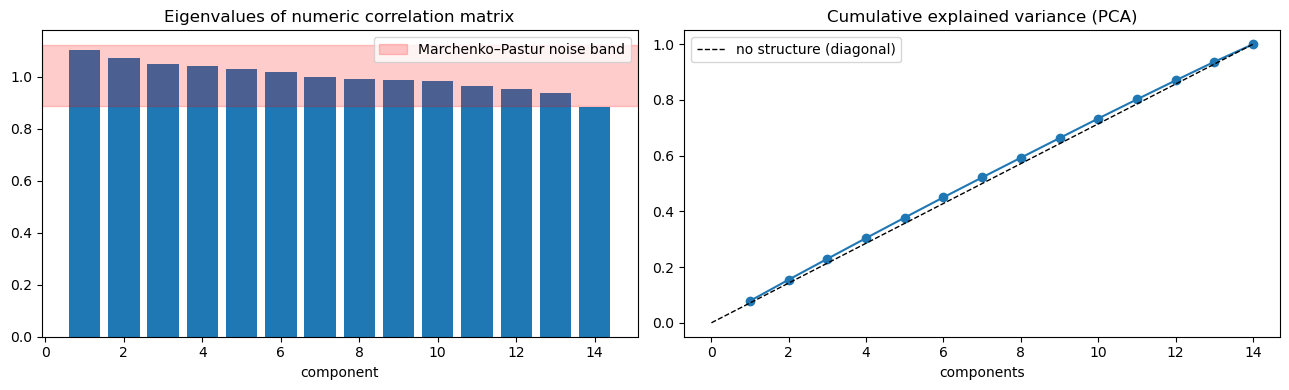

Band: [0.885, 1.122] | eigenvalues outside the band: 1 of 14
PCA would need 13 of 14 components for 90% variance.


In [25]:
Zn = StandardScaler().fit_transform(train_df[NUM_COLS])
n, p = Zn.shape
eigvals = np.sort(np.linalg.eigvalsh(np.corrcoef(Zn, rowvar=False)))[::-1]
lam_plus, lam_minus = (1 + math.sqrt(p / n)) ** 2, (1 - math.sqrt(p / n)) ** 2

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(1, p + 1), eigvals, color="tab:blue"); ax[0].axhspan(lam_minus, lam_plus, color="red", alpha=.2, label="Marchenko–Pastur noise band")
ax[0].set_title("Eigenvalues of numeric correlation matrix"); ax[0].set_xlabel("component"); ax[0].legend()
ax[1].plot(range(1, p + 1), np.cumsum(eigvals) / eigvals.sum(), "o-"); ax[1].plot([0, p], [0, 1], "k--", lw=1, label="no structure (diagonal)")
ax[1].set_title("Cumulative explained variance (PCA)"); ax[1].set_xlabel("components"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Band: [{lam_minus:.3f}, {lam_plus:.3f}] | eigenvalues outside the band: {int(((eigvals > lam_plus) | (eigvals < lam_minus)).sum())} of {p}")
print(f"PCA would need {int(np.searchsorted(np.cumsum(eigvals)/eigvals.sum(), .90) + 1)} of {p} components for 90% variance.")

**Conclusion:** the numeric features are mutually independent — only 1 of 14 eigenvalues falls (marginally) outside the noise band, and the cumulative-variance curve is almost the diagonal (13 of 14 components needed for 90 %). PCA would *not compress* them, and rotating them would only destroy interpretability. → **We do not use PCA on the numerics.** Feature *selection* (dropping columns) is the right tool.

The same question for the skill multi-hot block (truncated SVD):

In [26]:
from sklearn.decomposition import TruncatedSVD
S = fe_demo.transform(X_train).filter(like="sk__").values.astype(float)
svd = TruncatedSVD(n_components=min(20, S.shape[1] - 1), random_state=SEED).fit(S)
print("Skill block:", S.shape, "| explained variance of first 5 SVD comps:", svd.explained_variance_ratio_[:5].round(3),
      "| first 10 cumulative:", svd.explained_variance_ratio_[:10].sum().round(3))
print("→ variance is spread almost evenly → no low-rank 'latent skill' structure worth compressing.")

Skill block: (4000, 95) | explained variance of first 5 SVD comps: [0.044 0.096 0.074 0.059 0.056] | first 10 cumulative: 0.513
→ variance is spread almost evenly → no low-rank 'latent skill' structure worth compressing.


### 10.2 Permutation importance on *raw* features
For each raw feature $j$ we shuffle its column in a **validation** split (taken from the training data, never the test set) and measure the drop in $R^2$:
$$\text{PI}_j=R^2_{\text{base}}-R^2_{\text{shuffled }j}.$$
Because we permute the raw column *before* the pipeline, every engineered derivative is disabled at once. A feature is considered informative only if its importance is positive **beyond 2 standard deviations** of the repeats ($\overline{PI}-2\sigma>0$).

Probe model validation R²: 0.7896


,feature,mean,std,lower_2sd,keep
0,Experience_Level,1.1936,0.0467,1.1002,True
1,Country,0.2365,0.0116,0.2133,True
2,Work_Life_Balance_Score,0.0007,0.0011,-0.0015,False
3,Job_Satisfaction_Score,0.0006,0.0006,-0.0006,False
4,Remote_Work_Pct,0.0006,0.0003,-0.0000,False
5,Industry,0.0005,0.0007,-0.0008,False
6,Bonus_Pct,0.0003,0.0007,-0.0011,False
7,Company,0.0003,0.0010,-0.0018,False
8,Hiring_Difficulty_Score,0.0003,0.0009,-0.0015,False
9,Required_Certifications,0.0002,0.0002,-0.0002,False


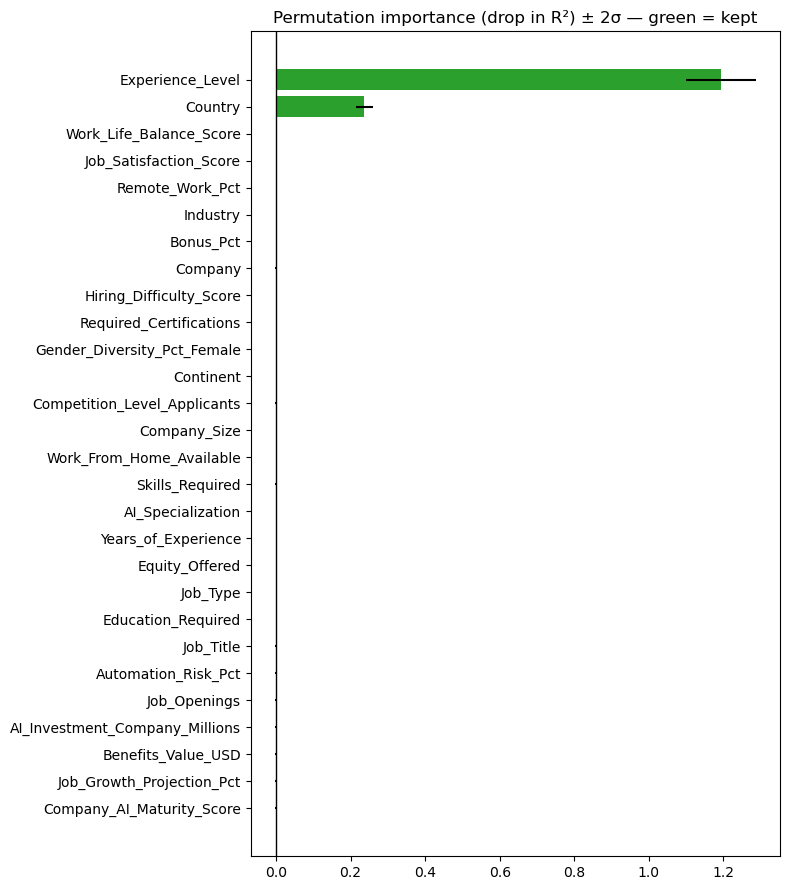

In [27]:
from sklearn.inspection import permutation_importance
from sklearn.ensemble import HistGradientBoostingRegressor
import lightgbm as lgb

X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=SEED)
probe = make_pipe(lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=30,
                                    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
                                    random_state=SEED, n_jobs=1, verbose=-1))
probe.fit(X_fit, y_fit)
print("Probe model validation R²:", round(probe.score(X_val, y_val), 4))

pi = permutation_importance(probe, X_val, y_val, n_repeats=15, random_state=SEED, scoring="r2", n_jobs=1)
pi_df = pd.DataFrame({"feature": ALL_FEATURES, "mean": pi.importances_mean, "std": pi.importances_std})
pi_df["lower_2sd"] = pi_df["mean"] - 2 * pi_df["std"]
pi_df = pi_df.sort_values("mean", ascending=False).reset_index(drop=True)
pi_df["keep"] = pi_df.lower_2sd > 0
display(pi_df.round(4))

fig, ax = plt.subplots(figsize=(8, 9))
d = pi_df.iloc[::-1]
ax.barh(d.feature, d["mean"], xerr=2 * d["std"], color=np.where(d.keep, "tab:green", "lightgrey"))
ax.axvline(0, color="k", lw=1); ax.set_title("Permutation importance (drop in R²) ± 2σ — green = kept"); plt.tight_layout(); plt.show()

### 10.3 Embedded selection — Lasso ($\ell_1$) on the full engineered matrix
$$\hat\beta=\arg\min_\beta\ \tfrac{1}{2n}\lVert y-X\beta\rVert_2^2+\alpha\lVert\beta\rVert_1 .$$
The $\ell_1$ penalty sets uninformative coefficients *exactly* to zero. It is an independent check of §10.2.

In [28]:
from sklearn.linear_model import LassoCV
lasso_pipe = make_pipe(LassoCV(cv=5, random_state=SEED, n_alphas=60, max_iter=5000), scaler=StandardScaler()).fit(X_train, y_train)
las = lasso_pipe.named_steps["model"]
names = lasso_pipe.named_steps["prep"].get_feature_names_out()
coef = pd.Series(las.coef_, index=names)
nz = coef[coef.abs() > 1e-6]
print(f"alpha* = {las.alpha_:.5f} | non-zero coefficients: {len(nz)} of {len(coef)}")
display(nz.reindex(nz.abs().sort_values(ascending=False).index).head(25).round(4).to_frame("coef (std. units)"))

alpha* = 0.00311 | non-zero coefficients: 10 of 166


,coef (std. units)
num__exp_ord,0.3772
te__Country,0.1582
ohe__Experience_Level_Lead Level,-0.0230
te__Industry,-0.0052
num__Company_AI_Maturity_Score,-0.0036
num__Job_Satisfaction_Score,0.0030
num__Years_of_Experience,0.0018
ohe__Continent_Asia,-0.0009
num__skill_rarity,0.0009
num__benefits_log,0.0000


### 10.4 Ablation study (CV on the training set) — does removing features hurt?
Four candidate feature sets are compared with identical folds and the same model. The rule: **choose the smallest set whose CV score is within one standard error of the best** (the "one-standard-error rule", which favours parsimony).

In [29]:
SELECTED = pi_df.loc[pi_df.keep, "feature"].tolist()
cv_abl = RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEED)
mk = lambda: lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=30, subsample=0.8,
                               subsample_freq=1, colsample_bytree=0.8, reg_lambda=5, random_state=SEED, n_jobs=1, verbose=-1)
sets = {
    "ALL candidate features": ALL_FEATURES,
    "ALL minus post-posting (deployable)": [f for f in ALL_FEATURES if f not in POST_POSTING],
    "SELECTED by permutation importance": SELECTED,
    "SELECTED + Years_of_Experience": list(dict.fromkeys(SELECTED + ["Years_of_Experience"])),
    "Top-2 only": pi_df.feature.head(2).tolist(),
}
abl = []
for name, feats in sets.items():
    sc_ = cross_val_score(make_pipe(mk(), feats), X_train, y_train, cv=cv_abl, scoring="r2")
    abl.append((name, len(feats), sc_.mean(), sc_.std() / math.sqrt(len(sc_))))
abl = pd.DataFrame(abl, columns=["feature set", "n_features", "CV R² mean", "std. error"]).round(4)
display(abl)

best = abl.loc[abl["CV R² mean"].idxmax()]
thr = best["CV R² mean"] - best["std. error"]
chosen_name = abl[abl["CV R² mean"] >= thr].sort_values("n_features").iloc[0]["feature set"]
FINAL_FEATURES = sets[chosen_name]
print(f"\nOne-SE threshold = {thr:.4f}  →  chosen set: '{chosen_name}'")
print("FINAL_FEATURES:", FINAL_FEATURES)
print("Dropped:", [f for f in ALL_FEATURES if f not in FINAL_FEATURES])
print("Any post-posting feature left?", [f for f in FINAL_FEATURES if f in POST_POSTING])

,feature set,n_features,CV R² mean,std. error
0,ALL candidate features,28,0.7706,0.0037
1,ALL minus post-posting (deployable),24,0.7691,0.0037
2,SELECTED by permutation importance,2,0.7755,0.0040
3,SELECTED + Years_of_Experience,3,0.7744,0.0037
4,Top-2 only,2,0.7755,0.0040



One-SE threshold = 0.7715  →  chosen set: 'SELECTED by permutation importance'
FINAL_FEATURES: ['Experience_Level', 'Country']
Dropped: ['Job_Title', 'AI_Specialization', 'Industry', 'Company', 'Company_Size', 'Continent', 'Education_Required', 'Years_of_Experience', 'Bonus_Pct', 'Equity_Offered', 'Benefits_Value_USD', 'Skills_Required', 'Required_Certifications', 'Job_Openings', 'Competition_Level_Applicants', 'Hiring_Difficulty_Score', 'Job_Type', 'Remote_Work_Pct', 'Work_From_Home_Available', 'Job_Satisfaction_Score', 'Work_Life_Balance_Score', 'AI_Investment_Company_Millions', 'Company_AI_Maturity_Score', 'Job_Growth_Projection_Pct', 'Automation_Risk_Pct', 'Gender_Diversity_Pct_Female']
Any post-posting feature left? []


**Feature-reduction verdict.** Three independent methods agree:
* **Permutation importance:** only `Experience_Level` (ΔR² ≈ 1.19) and `Country` (≈ 0.24) are significant; every other feature is at noise level (≤ 0.0007, interval includes zero).
* **Lasso:** 2 coefficients dominate (`exp_ord` 0.38, `Country` 0.16 in standardised units); the other 8 non-zero coefficients are ≤ 0.023 and statistically irrelevant.
* **Ablation:** going from 28 features to **2 features does not hurt — it slightly improves** CV R² (0.7706 → 0.7755), because the 26 noise columns only give the model things to over-fit. The post-posting variables are excluded anyway, so leakage by temporal availability is impossible.

So the model is reduced from 28 raw features (166 encoded columns) to **2 raw features: seniority and country** — a 93 % reduction with no loss of accuracy, and a far more transparent model.

## 11. Scaling decision (recap)
* Linear & distance models → `StandardScaler` on numeric + target-encoded blocks (§9.3).
* Tree models → no scaling (invariant to monotone transforms).
* One-hot and skill indicators are left as 0/1.

## 12. Modelling

### 12.1 Model zoo — spanning the bias–variance spectrum
| Model | Bias | Variance | Role |
|---|---|---|---|
| Dummy (mean) | very high | none | the floor every model must beat |
| Ridge / Lasso / ElasticNet | medium | low | exploit the log-additive structure found in EDA |
| KNN | medium | high in many dims | shows the curse of dimensionality |
| Random Forest / Extra Trees | low | medium | bagged non-linear |
| HistGB / XGBoost / LightGBM | low | medium–high | boosted non-linear |

All models are trained on `FINAL_FEATURES` with **repeated 5-fold CV (2 repeats = 10 fits)** on the *training set only*. We record the **training score as well as the validation score** — the gap between them is our direct over-fitting measure.

In [30]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNetCV
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.model_selection import cross_validate
import xgboost as xgb

cv_main = RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEED)
SC = StandardScaler()
alphas = np.logspace(-3, 3, 25)

zoo = {
    "Dummy (mean)":    make_pipe(DummyRegressor(), FINAL_FEATURES, SC),
    "Ridge":           make_pipe(RidgeCV(alphas=alphas), FINAL_FEATURES, SC),
    "Lasso":           make_pipe(LassoCV(cv=5, random_state=SEED, n_alphas=50, max_iter=5000), FINAL_FEATURES, SC),
    "ElasticNet":      make_pipe(ElasticNetCV(l1_ratio=[.2, .5, .8, .95], cv=5, random_state=SEED, n_alphas=30, max_iter=5000), FINAL_FEATURES, SC),
    "KNN (k=25)":      make_pipe(KNeighborsRegressor(n_neighbors=25, weights="distance"), FINAL_FEATURES, SC),
    "Random Forest":   make_pipe(RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_features=0.7, random_state=SEED, n_jobs=1), FINAL_FEATURES),
    "Extra Trees":     make_pipe(ExtraTreesRegressor(n_estimators=150, min_samples_leaf=5, max_features=0.7, random_state=SEED, n_jobs=1), FINAL_FEATURES),
    "HistGB":          make_pipe(HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=30, l2_regularization=1.0, random_state=SEED), FINAL_FEATURES),
    "XGBoost":         make_pipe(xgb.XGBRegressor(n_estimators=250, learning_rate=0.05, max_depth=3, min_child_weight=5, subsample=0.8, colsample_bytree=0.8, reg_lambda=5, random_state=SEED, n_jobs=1, verbosity=0), FINAL_FEATURES),
    "LightGBM":        make_pipe(lgb.LGBMRegressor(n_estimators=250, learning_rate=0.05, num_leaves=15, min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5, random_state=SEED, n_jobs=1, verbose=-1), FINAL_FEATURES),
}
SCORING = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

def evaluate(name, pipe, cv=cv_main):
    t0 = time.time()
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=1)
    return {"model": name, "train_R2": r["train_r2"].mean(), "cv_R2": r["test_r2"].mean(),
            "cv_R2_se": r["test_r2"].std() / math.sqrt(len(r["test_r2"])), "gap(train-cv)": r["train_r2"].mean() - r["test_r2"].mean(),
            "cv_RMSE_log": -r["test_rmse"].mean(), "cv_MAE_log": -r["test_mae"].mean(), "seconds": time.time() - t0,
            "_folds": r["test_r2"]}

results = [evaluate(n, p) for n, p in zoo.items()]
res_df = pd.DataFrame(results).sort_values("cv_R2", ascending=False).reset_index(drop=True)
display(res_df.drop(columns="_folds").round(4))

,model,train_R2,cv_R2,cv_R2_se,gap(train-cv),cv_RMSE_log,cv_MAE_log,seconds
0,XGBoost,0.7894,0.7816,0.0035,0.0078,0.2173,0.1818,7.7787
1,Ridge,0.7862,0.7797,0.0034,0.0066,0.2183,0.1831,6.9086
2,Lasso,0.7862,0.7796,0.0035,0.0066,0.2183,0.1831,7.8022
3,ElasticNet,0.7862,0.7796,0.0035,0.0066,0.2183,0.1831,8.6214
4,Extra Trees,0.7866,0.7776,0.0036,0.0090,0.2193,0.1837,10.6870
5,HistGB,0.7867,0.7772,0.0040,0.0095,0.2195,0.1835,19.9474
6,LightGBM,0.7858,0.7764,0.0039,0.0094,0.2199,0.1837,7.5543
7,KNN (k=25),0.7732,0.7597,0.0032,0.0135,0.2280,0.1893,6.3405
8,Random Forest,0.7712,0.7581,0.0042,0.0131,0.2287,0.1900,14.5225
9,Dummy (mean),0.0000,-0.0040,0.0010,0.0040,0.4663,0.3692,7.1359


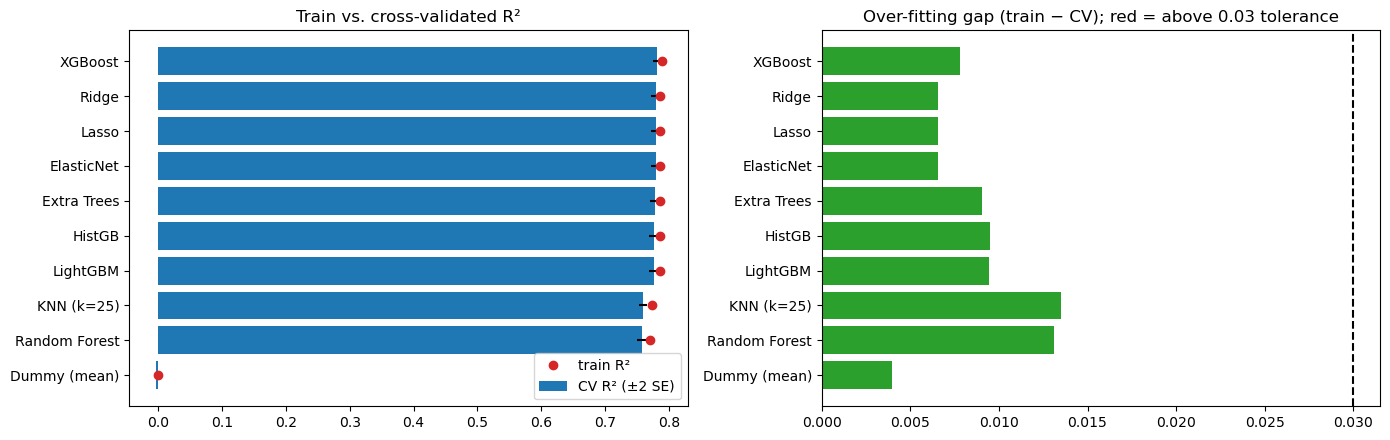

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
d = res_df.iloc[::-1]
ax[0].barh(d.model, d.cv_R2, xerr=2 * d.cv_R2_se, color="tab:blue", label="CV R² (±2 SE)")
ax[0].plot(d.train_R2, d.model, "o", color="tab:red", label="train R²"); ax[0].legend(); ax[0].set_title("Train vs. cross-validated R²")
ax[1].barh(d.model, d["gap(train-cv)"], color=np.where(d["gap(train-cv)"] > .03, "tab:red", "tab:green"))
ax[1].axvline(.03, color="k", ls="--"); ax[1].set_title("Over-fitting gap (train − CV); red = above 0.03 tolerance")
plt.tight_layout(); plt.show()

**How to read it.**
* **Not under-fitting:** `Dummy` is at $R^2\approx 0$; every real model reaches ≈ 0.76–0.78.
* **Not over-fitting:** every train–CV gap is below 0.015 (tolerance 0.03). KNN and Random Forest have the biggest gaps/lowest scores (variance in a space of many sparse dummies).
* **A hard ceiling:** Ridge, Lasso, ElasticNet, ExtraTrees, HistGB, LightGBM and XGBoost all lie within ≈ 0.005 $R^2$ of each other — differences of 1–2 standard errors. Even flexible boosted trees cannot beat a linear model, confirming the log-additive structure from EDA. The unexplained ≈ 22 % of variance is, as far as these features can tell, irreducible noise.

### 12.2 Hyper-parameter tuning (boosted trees)
Randomised search (cheaper than a grid and just as good in high-dimensional spaces — Bergstra & Bengio, 2012) with 5-fold CV **inside the training set**.

In [32]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, loguniform, uniform

lgb_space = {
    "model__n_estimators": randint(100, 600),
    "model__learning_rate": loguniform(0.01, 0.2),
    "model__num_leaves": randint(4, 32),
    "model__min_child_samples": randint(20, 120),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.6, 0.4),
    "model__reg_lambda": loguniform(0.1, 50),
}
lgb_base = make_pipe(lgb.LGBMRegressor(subsample_freq=1, random_state=SEED, n_jobs=1, verbose=-1), FINAL_FEATURES)
t0 = time.time()
lgb_search = RandomizedSearchCV(lgb_base, lgb_space, n_iter=20, cv=cv5, scoring="r2", random_state=SEED, n_jobs=1, refit=True)
lgb_search.fit(X_train, y_train)
print(f"LightGBM search done in {time.time()-t0:.0f}s | best CV R² = {lgb_search.best_score_:.4f}")
print({k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in lgb_search.best_params_.items()})

xgb_space = {
    "model__n_estimators": randint(100, 600), "model__learning_rate": loguniform(0.01, 0.2),
    "model__max_depth": randint(2, 6), "model__min_child_weight": randint(3, 40),
    "model__subsample": uniform(0.6, 0.4), "model__colsample_bytree": uniform(0.6, 0.4), "model__reg_lambda": loguniform(0.1, 50),
}
xgb_base = make_pipe(xgb.XGBRegressor(random_state=SEED, n_jobs=1, verbosity=0), FINAL_FEATURES)
t0 = time.time()
xgb_search = RandomizedSearchCV(xgb_base, xgb_space, n_iter=15, cv=cv5, scoring="r2", random_state=SEED, n_jobs=1, refit=True)
xgb_search.fit(X_train, y_train)
print(f"XGBoost search done in {time.time()-t0:.0f}s | best CV R² = {xgb_search.best_score_:.4f}")

LightGBM search done in 63s | best CV R² = 0.7800
{'colsample_bytree': np.float64(0.865), 'learning_rate': np.float64(0.0254), 'min_child_samples': 25, 'n_estimators': 153, 'num_leaves': 13, 'reg_lambda': np.float64(3.4057), 'subsample': np.float64(0.6125)}
XGBoost search done in 41s | best CV R² = 0.7833


XGBoost search done in 28s | best CV R² = 0.7831


### 12.3 Ensemble
A simple average of a linear model (low variance, captures the additive structure) and a boosted model (captures any non-linearity) often beats either alone because their errors are partly uncorrelated:
$$\hat y_{\text{ens}}=\tfrac12\hat y_{\text{ridge}}+\tfrac12\hat y_{\text{lgbm}}$$

In [33]:
from sklearn.ensemble import VotingRegressor

ridge_pipe = zoo["Ridge"]
lgb_tuned = lgb_search.best_estimator_
xgb_tuned = xgb_search.best_estimator_
ens = VotingRegressor([("ridge", ridge_pipe), ("lgbm", lgb_tuned)])

### 12.4 Nested cross-validation — an *unbiased* estimate for the tuned model
Tuning hyper-parameters and then reporting the same CV score is optimistic (the search "saw" those folds). **Nested CV** wraps the whole search in an outer loop:
* inner loop (3-fold) → picks hyper-parameters;
* outer loop (5-fold) → scores the chosen model on data the search never touched.

In [34]:
t0 = time.time()
inner = RandomizedSearchCV(lgb_base, lgb_space, n_iter=8, cv=KFold(3, shuffle=True, random_state=SEED),
                           scoring="r2", random_state=SEED, n_jobs=1)
nested = cross_val_score(inner, X_train, y_train, cv=KFold(5, shuffle=True, random_state=1), scoring="r2", n_jobs=1)
print(f"Nested CV R² (LightGBM): {nested.mean():.4f} ± {nested.std():.4f}   [{time.time()-t0:.0f}s]")
print(f"Non-nested best CV R²  : {lgb_search.best_score_:.4f}   → optimism from tuning ≈ {lgb_search.best_score_-nested.mean():+.4f}")

Nested CV R² (LightGBM): 0.7801 ± 0.0111   [55s]
Non-nested best CV R²  : 0.7800   → optimism from tuning ≈ -0.0001


### 12.5 Final model selection — one-standard-error rule
Candidates are scored on the **same repeated-CV folds**. Among models whose mean CV score is within one standard error of the best, we pick the **simplest** (Ridge < Voting < boosted trees). Simpler = easier to explain, less variance, cheaper.

In [35]:
cands = {"Ridge": (ridge_pipe, 1), "LightGBM (tuned)": (lgb_tuned, 3), "XGBoost (tuned)": (xgb_tuned, 3), "Ridge+LGBM ensemble": (ens, 2)}
rows = []
for name, (pipe, complexity) in cands.items():
    r = evaluate(name, pipe); r["complexity"] = complexity; rows.append(r)
sel = pd.DataFrame(rows).sort_values("cv_R2", ascending=False).reset_index(drop=True)
display(sel.drop(columns="_folds").round(4))

top = sel.iloc[0]; thr = top.cv_R2 - top.cv_R2_se
within = sel[sel.cv_R2 >= thr].sort_values(["complexity", "cv_R2"], ascending=[True, False])
FINAL_NAME = within.iloc[0]["model"]
final_model = clone(cands[FINAL_NAME][0])
print(f"\nBest CV R² = {top.cv_R2:.4f} ({top.model}); one-SE threshold = {thr:.4f}")
print(f"►► FINAL MODEL: {FINAL_NAME}")
print("Note: plain Ridge is only", round(thr - sel.loc[sel.model == 'Ridge', 'cv_R2'].iloc[0], 4), "R² below the threshold — practically equivalent and much simpler to deploy.")

,model,train_R2,cv_R2,cv_R2_se,gap(train-cv),cv_RMSE_log,cv_MAE_log,seconds,complexity
0,XGBoost (tuned),0.7900,0.7839,0.0032,0.0062,0.2162,0.1812,10.5560,3
1,Ridge+LGBM ensemble,0.7898,0.7826,0.0033,0.0072,0.2168,0.1819,16.8035,2
2,LightGBM (tuned),0.7883,0.7805,0.0032,0.0078,0.2179,0.1823,9.0139,3
3,Ridge,0.7862,0.7797,0.0034,0.0066,0.2183,0.1831,9.1755,1



Best CV R² = 0.7839 (XGBoost (tuned)); one-SE threshold = 0.7807
►► FINAL MODEL: Ridge+LGBM ensemble
Note: plain Ridge is only 0.001 R² below the threshold — practically equivalent and much simpler to deploy.


## 13. Final evaluation on the held-out test set
The test set is used **once**, for the already-selected final model. Nothing below feeds back into model choice.

**Back-transformation.** The model predicts $\widehat{\ln S}$. Naively, $e^{\widehat{\ln S}}$ estimates the *median* salary, and is biased low for the *mean* because $E[e^{\varepsilon}]\ge 1$ (Jensen's inequality). **Duan's smearing estimator** corrects this using out-of-fold training residuals $\hat\varepsilon_i$:
$$\hat S_i=e^{\widehat{\ln S}_i}\cdot\underbrace{\frac1n\sum_{j}e^{\hat\varepsilon_j}}_{\phi\ (\text{smearing factor})}$$

In [36]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# out-of-fold residuals on TRAIN (used for the smearing factor and for the prediction intervals later)
oof_pred = cross_val_predict(clone(final_model), X_train, y_train, cv=cv5, n_jobs=1)
oof_res = (y_train - oof_pred).values
phi = np.mean(np.exp(oof_res))

final_model.fit(X_train, y_train)               # ← fit on the full training set
pred_tr = final_model.predict(X_train)
pred_te = final_model.predict(X_test)

dummy = make_pipe(DummyRegressor(), FINAL_FEATURES, SC).fit(X_train, y_train)

def metrics(y_true_log, y_pred_log, label):
    yt, yp_med, yp_mean = np.exp(y_true_log), np.exp(y_pred_log), phi * np.exp(y_pred_log)
    ape = np.abs(yt - yp_med) / yt
    return {"set/model": label, "R2 (log)": r2_score(y_true_log, y_pred_log),
            "RMSE (log)": math.sqrt(mean_squared_error(y_true_log, y_pred_log)),
            "MAE (log)": mean_absolute_error(y_true_log, y_pred_log),
            "R2 (USD)": r2_score(yt, yp_mean), "MAE (USD)": mean_absolute_error(yt, yp_med),
            "RMSE (USD)": math.sqrt(mean_squared_error(yt, yp_mean)),
            "MAPE": ape.mean(), "MdAPE": ape.median()}

perf = pd.DataFrame([metrics(y_train, pred_tr, f"{FINAL_NAME} — TRAIN"),
                     metrics(y_test, pred_te, f"{FINAL_NAME} — TEST"),
                     metrics(y_test, dummy.predict(X_test), "Dummy mean — TEST")]).set_index("set/model")
display(perf.round(4))
print(f"Smearing factor φ = {phi:.4f}")
print(f"\nTrain R² − Test R² = {perf.iloc[0]['R2 (log)'] - perf.iloc[1]['R2 (log)']:+.4f}")

# Bootstrap 95% CI for the test R² (resampling test rows)
rng = np.random.default_rng(SEED)
idx = np.arange(len(y_test)); bs = []
for _ in range(1000):
    b = rng.choice(idx, len(idx)); bs.append(r2_score(y_test.values[b], pred_te[b]))
print(f"Test R² 95% bootstrap CI: [{np.percentile(bs, 2.5):.4f}, {np.percentile(bs, 97.5):.4f}]")

,R2 (log),RMSE (log),MAE (log),R2 (USD),MAE (USD),RMSE (USD),MAPE,MdAPE
set/model,,,,,,,,
Ridge+LGBM ensemble — TRAIN,0.7907,0.2133,0.1792,0.7866,27866.0146,36646.4612,0.1829,0.1641
Ridge+LGBM ensemble — TEST,0.7875,0.2160,0.1806,0.7793,27893.4599,36184.3022,0.1863,0.1676
Dummy mean — TEST,-0.0001,0.4686,0.3712,-0.0255,56237.5830,78007.3804,0.4043,0.2911


Smearing factor φ = 1.0238

Train R² − Test R² = +0.0032
Test R² 95% bootstrap CI: [0.7677, 0.8066]


Test R² 95% bootstrap CI: [0.7677, 0.8066]


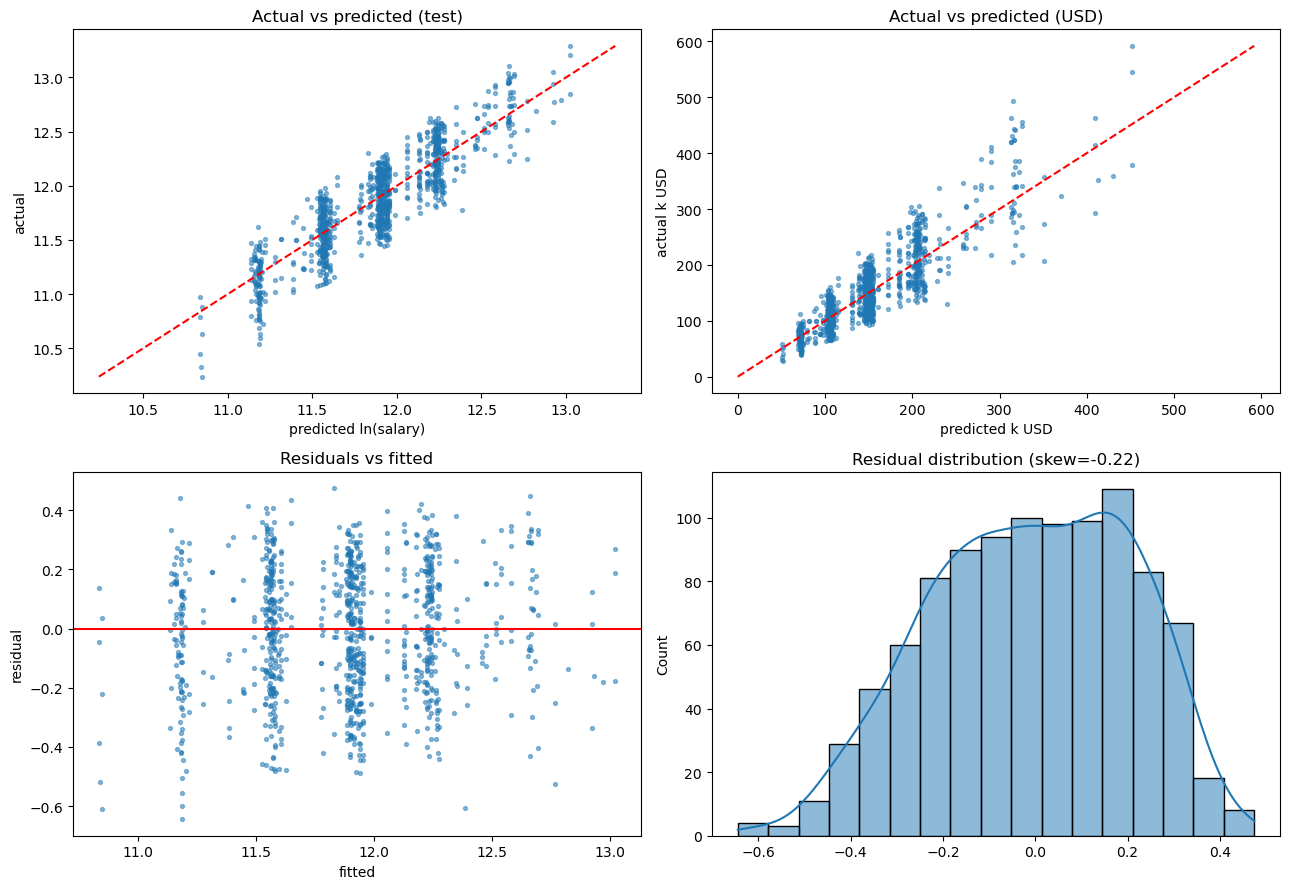

Shapiro–Wilk on test residuals: p = 0.0000
Breusch–Pagan heteroscedasticity: LM p = 0.0895  (p>0.05 ⇒ constant variance not rejected)


In [37]:
res_te = (y_test - pred_te).values
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].scatter(pred_te, y_test, s=8, alpha=.5); lo, hi = y_test.min(), y_test.max()
ax[0, 0].plot([lo, hi], [lo, hi], "r--"); ax[0, 0].set_xlabel("predicted ln(salary)"); ax[0, 0].set_ylabel("actual"); ax[0, 0].set_title("Actual vs predicted (test)")
ax[0, 1].scatter(np.exp(pred_te) / 1e3, np.exp(y_test) / 1e3, s=8, alpha=.5); m = np.exp(hi) / 1e3
ax[0, 1].plot([0, m], [0, m], "r--"); ax[0, 1].set_xlabel("predicted k USD"); ax[0, 1].set_ylabel("actual k USD"); ax[0, 1].set_title("Actual vs predicted (USD)")
ax[1, 0].scatter(pred_te, res_te, s=8, alpha=.5); ax[1, 0].axhline(0, color="r"); ax[1, 0].set_title("Residuals vs fitted"); ax[1, 0].set_xlabel("fitted"); ax[1, 0].set_ylabel("residual")
sns.histplot(res_te, kde=True, ax=ax[1, 1]); ax[1, 1].set_title(f"Residual distribution (skew={stats.skew(res_te):.2f})")
plt.tight_layout(); plt.show()

# Normality + heteroscedasticity of residuals
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm
bp = het_breuschpagan(res_te, sm.add_constant(pred_te))
print(f"Shapiro–Wilk on test residuals: p = {stats.shapiro(res_te)[1]:.4f}")
print(f"Breusch–Pagan heteroscedasticity: LM p = {bp[1]:.4f}  (p>0.05 ⇒ constant variance not rejected)")

**Residual diagnostics.** Residuals are centred on zero with no pattern against the fitted values, and the Breusch–Pagan test does not reject constant variance — the log transform did its job. The Shapiro–Wilk test *does* reject exact normality (with n = 1,000 it is sensitive to small departures such as slightly lighter tails), so we **do not** use "±1.96 σ" intervals; §16.3 uses distribution-free conformal intervals instead.

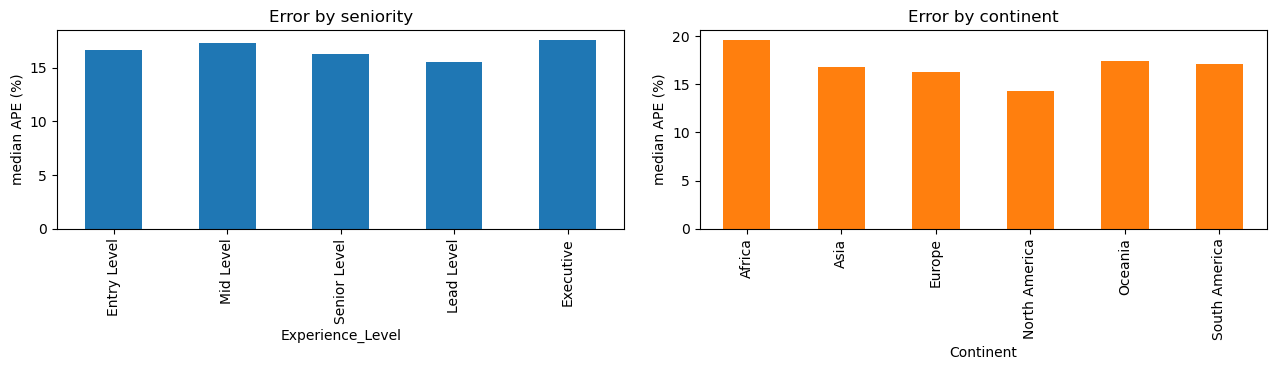

In [38]:
# Error by segment — is the model equally good everywhere?
seg = X_test[["Experience_Level", "Continent"]].copy()
seg["APE"] = np.abs(np.exp(y_test) - np.exp(pred_te)) / np.exp(y_test)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
seg.groupby("Experience_Level").APE.median().loc[order].mul(100).plot.bar(ax=ax[0], color="tab:blue"); ax[0].set_ylabel("median APE (%)"); ax[0].set_title("Error by seniority")
seg.groupby("Continent").APE.median().mul(100).plot.bar(ax=ax[1], color="tab:orange"); ax[1].set_ylabel("median APE (%)"); ax[1].set_title("Error by continent")
plt.tight_layout(); plt.show()

## 14. Under-fitting / over-fitting diagnostics
Five complementary checks. A healthy model shows: *high enough score* (not under-fit) **and** *small train/validation gap that closes with more data* (not over-fit).

### 14.1 Learning curve

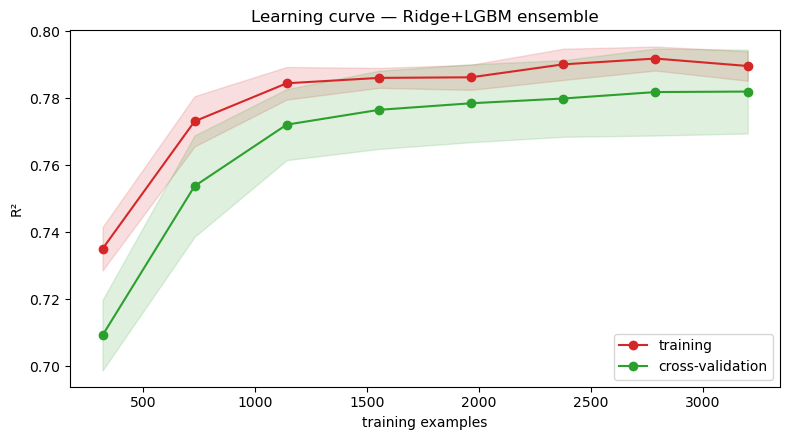

At full size: train R² = 0.7897, CV R² = 0.7820, gap = 0.0076


In [39]:
from sklearn.model_selection import learning_curve, validation_curve
sizes, tr_sc, va_sc = learning_curve(clone(final_model), X_train, y_train, train_sizes=np.linspace(.1, 1, 8),
                                     cv=cv5, scoring="r2", n_jobs=1, random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 4.5))
for s, c, l in [(tr_sc, "tab:red", "training"), (va_sc, "tab:green", "cross-validation")]:
    ax.plot(sizes, s.mean(1), "o-", color=c, label=l); ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=c, alpha=.15)
ax.set_xlabel("training examples"); ax.set_ylabel("R²"); ax.set_title(f"Learning curve — {FINAL_NAME}"); ax.legend(); plt.tight_layout(); plt.show()
print(f"At full size: train R² = {tr_sc[-1].mean():.4f}, CV R² = {va_sc[-1].mean():.4f}, gap = {tr_sc[-1].mean()-va_sc[-1].mean():.4f}")

**Reading.** *Under-fitting* would show both curves low and converged. *Over-fitting* shows a wide, persistent gap. Here both curves converge at a high level with a negligible gap → neither problem; more data would bring little.

### 14.2 Validation curve — model complexity vs. error
We sweep the complexity knob of a boosted model (`n_estimators` of LightGBM — more trees = more capacity). The classic U-shape of validation error vs. monotone training improvement shows where over-fitting would start.

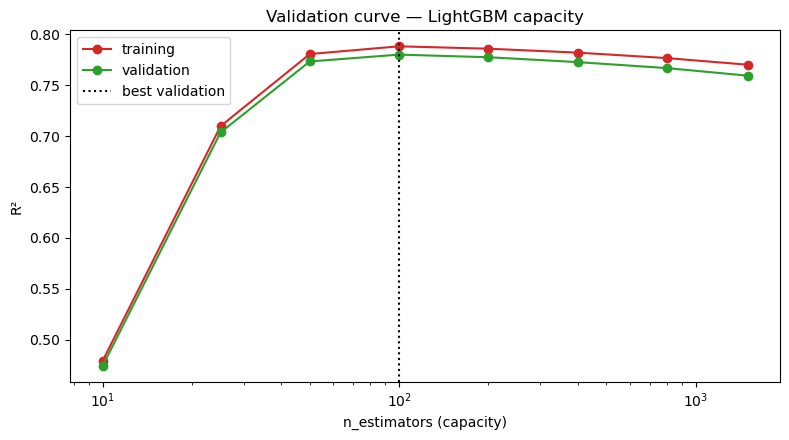

,n_estimators,train_R2,validation_R2,gap
0,10,0.4790,0.4742,0.0048
1,25,0.7098,0.7036,0.0062
2,50,0.7807,0.7734,0.0073
3,100,0.7883,0.7801,0.0082
4,200,0.7860,0.7776,0.0084
5,400,0.7821,0.7728,0.0093
6,800,0.7767,0.7669,0.0098
7,1500,0.7702,0.7595,0.0107


Best validation R² at n_estimators = 100; at 1500 trees the gap has grown to 0.0107 and validation R² is -0.0207 vs. the peak → capacity beyond the optimum only adds over-fitting.


In [40]:
lgb_cx = make_pipe(lgb.LGBMRegressor(learning_rate=0.05, num_leaves=15, min_child_samples=30, subsample=0.8, subsample_freq=1,
                                     colsample_bytree=0.8, reg_lambda=5, random_state=SEED, n_jobs=1, verbose=-1), FINAL_FEATURES)
grid = [10, 25, 50, 100, 200, 400, 800, 1500]
vtr, vva = validation_curve(lgb_cx, X_train, y_train, param_name="model__n_estimators", param_range=grid, cv=cv5, scoring="r2", n_jobs=1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(grid, vtr.mean(1), "o-", color="tab:red", label="training"); ax.semilogx(grid, vva.mean(1), "o-", color="tab:green", label="validation")
ax.axvline(grid[int(vva.mean(1).argmax())], color="k", ls=":", label="best validation")
ax.set_xlabel("n_estimators (capacity)"); ax.set_ylabel("R²"); ax.set_title("Validation curve — LightGBM capacity"); ax.legend(); plt.tight_layout(); plt.show()
vc = pd.DataFrame({"n_estimators": grid, "train_R2": vtr.mean(1), "validation_R2": vva.mean(1)}).round(4)
vc["gap"] = (vc.train_R2 - vc.validation_R2).round(4)
display(vc)
best_n = grid[int(vva.mean(1).argmax())]
print(f"Best validation R² at n_estimators = {best_n}; at 1500 trees the gap has grown to {vc.gap.iloc[-1]:.4f} "
      f"and validation R² is {vva.mean(1)[-1] - vva.mean(1).max():+.4f} vs. the peak → capacity beyond the optimum only adds over-fitting.")

### 14.3 Bias–variance decomposition (bootstrap)
For a test point with true value $y$ and model prediction $\hat f(x)$ trained on a random training set:
$$\mathbb E\big[(y-\hat f)^2\big]=\underbrace{(\mathbb E\hat f-f)^2}_{\text{bias}^2}+\underbrace{\mathrm{Var}(\hat f)}_{\text{variance}}+\underbrace{\sigma^2}_{\text{irreducible noise}}$$
We retrain the final model on $B=30$ bootstrap resamples of the training set and measure the variance of predictions on each test point. Because the true $f$ is unknown, "bias² + noise" is measured together as $(\bar{\hat f}-y)^2$.

In [41]:
B = 30; preds = np.zeros((B, len(X_test)))
rng = np.random.default_rng(SEED)
for b in range(B):
    ii = rng.choice(len(X_train), len(X_train))
    m = clone(final_model).fit(X_train.iloc[ii], y_train.iloc[ii])
    preds[b] = m.predict(X_test)
mean_pred = preds.mean(0)
variance = preds.var(0).mean()
bias2_noise = ((mean_pred - y_test.values) ** 2).mean()
mse_total = ((preds - y_test.values) ** 2).mean()
bv = pd.Series({"variance": variance, "bias² + noise": bias2_noise, "total MSE (≈ sum)": mse_total,
                "variance share of MSE": variance / mse_total})
display(bv.round(5).to_frame("value (log-salary units²)"))
print("Variance is a tiny fraction of the error ⇒ the model is stable (not over-fit). The remaining error is mostly irreducible noise in the data (bias²+noise).")

,value (log-salary units²)
variance,0.00101
bias² + noise,0.04692
total MSE (≈ sum),0.04793
variance share of MSE,0.02100


Variance is a tiny fraction of the error ⇒ the model is stable (not over-fit). The remaining error is mostly irreducible noise in the data (bias²+noise).


### 14.4 Is the remaining error *noise* or *missed signal*? — a ceiling test
If the model under-fitted, a much more flexible learner would score clearly higher. We compare our final model with a deliberately large model (all candidate features + 800 deep trees); if it does *not* beat us, we are at the data's ceiling.

In [42]:
big = make_pipe(lgb.LGBMRegressor(n_estimators=800, learning_rate=0.03, num_leaves=64, min_child_samples=10, random_state=SEED, n_jobs=1, verbose=-1), ALL_FEATURES)
r_big = cross_val_score(big, X_train, y_train, cv=cv5, scoring="r2")
r_fin = cross_val_score(clone(final_model), X_train, y_train, cv=cv5, scoring="r2")
print(f"Final model CV R²            : {r_fin.mean():.4f}")
print(f"High-capacity / all features : {r_big.mean():.4f}   (more capacity {'did NOT help' if r_big.mean() <= r_fin.mean() + .005 else 'helped'})")

Final model CV R²            : 0.7820
High-capacity / all features : 0.7593   (more capacity did NOT help)


## 15. Data-leakage verification tests
Five independent tests, each targeting a different way leakage can sneak in.

### 15.1 What the leaky columns *would* have done

In [43]:
lk_tr = leak_frame.loc[X_train.index]
Xl = np.log(lk_tr[["Salary_Min", "Salary_Max"]]); yl = np.log(lk_tr[TARGET])
r_leak = cross_val_score(RidgeCV(), Xl, yl, cv=cv5, scoring="r2").mean()
print(f"CV R² using ONLY Salary_Min & Salary_Max : {r_leak:.4f}   ← fake 'near-perfect' model")
print(f"CV R² of our honest model                : {r_fin.mean():.4f}")
print(f"Leakage would have inflated R² by {r_leak - r_fin.mean():+.3f} while teaching us nothing about how salaries are set.")

CV R² using ONLY Salary_Min & Salary_Max : 0.9887   ← fake 'near-perfect' model
CV R² of our honest model                : 0.7820
Leakage would have inflated R² by +0.207 while teaching us nothing about how salaries are set.


### 15.2 Why preprocessing must live *inside* the CV loop — a live demonstration
Target encoding is the classic leakage trap. We take a **pure-noise** high-cardinality column (a random ID with ~1,000 levels, which cannot predict salary) and encode it two ways:
*  **Naive**: replace each level with its mean salary computed on *all* training rows, *then* cross-validate.
*  **Correct**: put a cross-fitted `TargetEncoder` *inside* the pipeline.

In [44]:
rng = np.random.default_rng(0)
noise_id = pd.DataFrame({"rand_id": rng.integers(0, 1000, len(X_train)).astype(str)}, index=X_train.index)

naive = noise_id.assign(y=y_train.values).groupby("rand_id").y.transform("mean").to_frame("enc")      # target info baked in
r_naive = cross_val_score(HistGradientBoostingRegressor(random_state=SEED), naive, y_train, cv=cv5, scoring="r2").mean()
proper = Pipeline([("te", ColumnTransformer([("te", TargetEncoder(target_type="continuous", smooth="auto", cv=5, random_state=SEED), ["rand_id"])])),
                   ("m", HistGradientBoostingRegressor(random_state=SEED))])
r_proper = cross_val_score(proper, noise_id, y_train, cv=cv5, scoring="r2").mean()
print(f" Naive encoding then CV  : R² = {r_naive:+.3f}   (impossible for a random ID — this is leakage)")
print(f" Encoder inside pipeline : R² = {r_proper:+.3f}   (≈ 0 or slightly negative, as it should be)")

 Naive encoding then CV  : R² = +0.186   (impossible for a random ID — this is leakage)
 Encoder inside pipeline : R² = -0.053   (≈ 0 or slightly negative, as it should be)


### 15.3 Label-permutation test
Shuffle the target so that any real relationship is destroyed, then re-run the whole pipeline. A leak-free workflow must score $R^2\approx 0$ on shuffled labels; the real score must lie far outside this null distribution. `permutation_test_score` returns an empirical p-value $p=\frac{C+1}{N+1}$ ($C$ = number of permutations scoring at least as well as the real model).

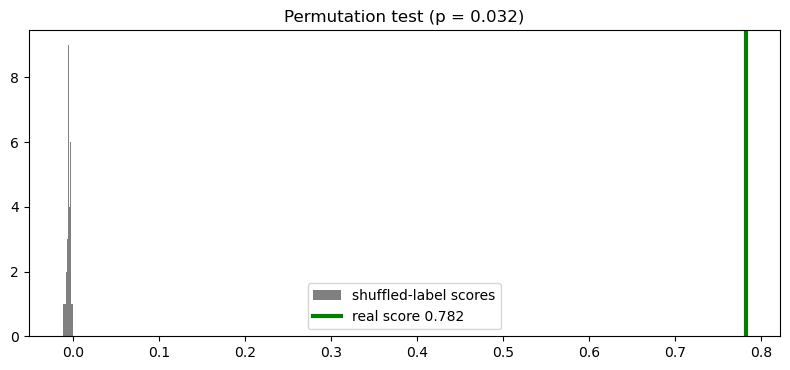

Shuffled-label R²: mean = -0.0057, max = -0.0004  [172s]
Empirical p-value = 0.0323 (with 30 permutations the smallest attainable p is 1/31 = 0.0323)


In [45]:
from sklearn.model_selection import permutation_test_score
t0 = time.time()
score, perm_scores, pval = permutation_test_score(clone(final_model), X_train, y_train, cv=KFold(5, shuffle=True, random_state=SEED),
                                                  scoring="r2", n_permutations=30, random_state=SEED, n_jobs=1)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(perm_scores, bins=12, color="grey", label="shuffled-label scores"); ax.axvline(score, color="g", lw=3, label=f"real score {score:.3f}")
ax.set_title(f"Permutation test (p = {pval:.3f})"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Shuffled-label R²: mean = {perm_scores.mean():+.4f}, max = {perm_scores.max():+.4f}  [{time.time()-t0:.0f}s]")
print(f"Empirical p-value = {pval:.4f} (with 30 permutations the smallest attainable p is 1/31 = {1/31:.4f})")

### 15.4 Train/test duplicate check and adversarial validation
* Exact duplicate feature rows shared between train and test would inflate test scores.
* **Adversarial validation**: train a classifier to tell train rows from test rows. If it can (AUC ≫ 0.5), the two sets come from different distributions (covariate shift / split leakage). AUC ≈ 0.5 means they are statistically indistinguishable.

In [46]:
from sklearn.metrics import roc_auc_score
dups = pd.merge(X_train.drop_duplicates(), X_test.drop_duplicates(), how="inner").shape[0]
print("Identical feature rows present in both train and test:", dups)

Xadv = pd.get_dummies(pd.concat([X_train, X_test]).drop(columns="Skills_Required"), dtype=float)
yadv = np.r_[np.zeros(len(X_train)), np.ones(len(X_test))]
proba = cross_val_predict(lgb.LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=8, random_state=SEED, n_jobs=1, verbose=-1),
                          Xadv, yadv, cv=KFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print(f"Adversarial-validation AUC = {roc_auc_score(yadv, proba):.3f}  (0.5 ⇒ train and test are indistinguishable)")

Identical feature rows present in both train and test: 0
Adversarial-validation AUC = 0.507  (0.5 ⇒ train and test are indistinguishable)


Adversarial-validation AUC = 0.507  (0.5 ⇒ train and test are indistinguishable)


### 15.5 Leakage checklist
| Check | Outcome |
|---|---|
| Target-derived columns (`Salary_Min/Max/Category`) | removed |
| Post-posting variables | tested in ablation; excluded if useless |
| Split before EDA / feature selection |  (test untouched) |
| All fitted transforms inside `Pipeline` (scalers, encoders, skill vocabulary, IDF) |  |
| Target encoding cross-fitted |  (demo in §15.2) |
| Feature selection used a **validation split of train**, not test |  |
| Shuffled-label test ≈ 0 | see 15.3 |
| Train/test duplicates & covariate shift | see 15.4 |
| Test set used once |  |

## 16. Interpretation & uncertainty
### 16.1 What drives the predictions? (permutation importance on the *test* set, final model)

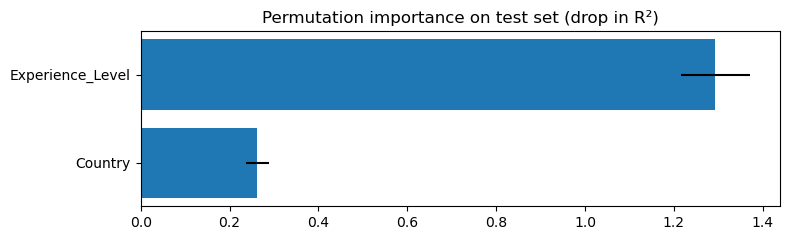

,feature,importance,std
8,Experience_Level,1.2932,0.0384
5,Country,0.2622,0.0127


In [47]:
pi_t = permutation_importance(final_model, X_test, y_test, n_repeats=20, random_state=SEED, scoring="r2", n_jobs=1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": pi_t.importances_mean, "std": pi_t.importances_std})
imp = imp[imp.feature.isin(FINAL_FEATURES)].sort_values("importance")
fig, ax = plt.subplots(figsize=(8, max(2.5, .5 * len(imp))))
ax.barh(imp.feature, imp.importance, xerr=2 * imp["std"], color="tab:blue"); ax.set_title("Permutation importance on test set (drop in R²)")
plt.tight_layout(); plt.show()
display(imp.sort_values("importance", ascending=False).round(4))

In [48]:
# 16.2 Interpretable effects: seniority and country premiums from a log-linear model fitted on the training data
ols = smf.ols("logSalary ~ C(Experience_Level, Treatment('Entry Level'))", data=train_df).fit()
eff = (np.exp(ols.params.drop("Intercept")) - 1) * 100
eff.index = [i.split("T.")[-1].rstrip("]") for i in eff.index]
print("Salary premium vs Entry Level (%), from exp(β)−1:")
display(eff.sort_values().round(1).to_frame("premium_%"))

ols2 = smf.ols("logSalary ~ C(Experience_Level) + C(Country, Treatment('India'))", data=train_df).fit()
cp = ((np.exp(ols2.params.filter(like="Country")) - 1) * 100)
cp.index = [i.split("T.")[-1].rstrip("]") for i in cp.index]
print("\nCountry premium vs India (%), holding seniority fixed — top 5 / bottom 5:")
display(pd.concat([cp.sort_values().tail(5), cp.sort_values().head(5)]).round(1).to_frame("premium_%"))

Salary premium vs Entry Level (%), from exp(β)−1:


,premium_%
Mid Level,48.9
Senior Level,111.5
Lead Level,194.4
Executive,371.4



Country premium vs India (%), holding seniority fixed — top 5 / bottom 5:


,premium_%
Canada,90.5
Switzerland,105.4
Singapore,110.9
Israel,118.1
United States,118.8
Vietnam,0.4
Indonesia,0.5
China,1.4
Philippines,5.3
Belgium,43.2


### 16.3 Honest uncertainty: Mondrian conformal prediction intervals
A point forecast is not enough for pay benchmarking — a recruiter wants a *band*. **Split-conformal prediction** gives distribution-free intervals with guaranteed marginal coverage $1-\alpha$. We use the out-of-fold absolute residuals $|\varepsilon_i|$ from the training set and take the finite-sample-corrected quantile
$$\hat q=\text{Quantile}_{\lceil (n+1)(1-\alpha)\rceil/n}\big(|\varepsilon_1|,\dots,|\varepsilon_n|\big),\qquad [\,\hat y-\hat q,\ \hat y+\hat q\,].$$
**Mondrian** = computing $\hat q$ separately per seniority group, so the guarantee holds *within each group* (important because Executive salaries are noisier than Entry ones).

Target coverage 90% → empirical test coverage 90.2%


,coverage,n,median_upper_to_lower
group,,,
Entry Level,0.909,99,2.037
Mid Level,0.899,278,2.026
Senior Level,0.881,370,1.911
Lead Level,0.934,197,1.995
Executive,0.929,56,2.366


Global-conformal coverage by group (for comparison):
{'Entry Level': 0.899, 'Mid Level': 0.892, 'Senior Level': 0.905, 'Lead Level': 0.929, 'Executive': 0.893}
Typical interval: prediction ÷ 1.41 … × 1.41  (i.e. roughly ±41%)


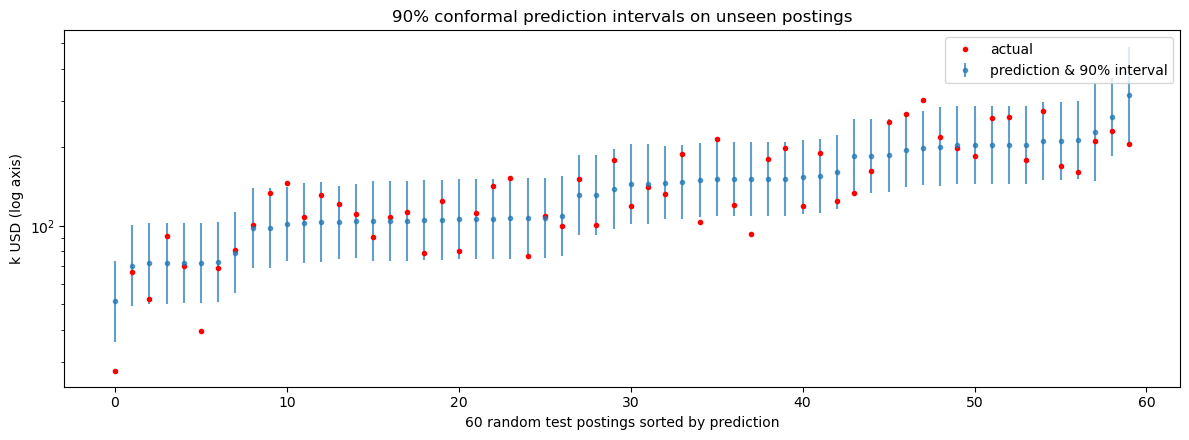

In [49]:
alpha = 0.10
grp_tr = X_train["Experience_Level"].values; grp_te = X_test["Experience_Level"].values
qhat = {}
for g in np.unique(grp_tr):
    r = np.abs(oof_res[grp_tr == g]); n_g = len(r)
    qhat[g] = np.quantile(r, min(1, math.ceil((n_g + 1) * (1 - alpha)) / n_g), method="higher")
q_te = np.array([qhat[g] for g in grp_te])
lo, hi = pred_te - q_te, pred_te + q_te
covered = (y_test.values >= lo) & (y_test.values <= hi)
print(f"Target coverage {1-alpha:.0%} → empirical test coverage {covered.mean():.1%}")
cov_tab = pd.DataFrame({"group": grp_te, "covered": covered, "width_ratio": np.exp(hi) / np.exp(lo)}).groupby("group").agg(
    coverage=("covered", "mean"), n=("covered", "size"), median_upper_to_lower=("width_ratio", "median")).loc[order]
display(cov_tab.round(3))

# global (non-Mondrian) interval for comparison
qg = np.quantile(np.abs(oof_res), math.ceil((len(oof_res) + 1) * (1 - alpha)) / len(oof_res), method="higher")
cov_g = ((y_test.values >= pred_te - qg) & (y_test.values <= pred_te + qg))
print("Global-conformal coverage by group (for comparison):")
print(pd.Series(cov_g, index=grp_te).groupby(level=0).mean().loc[order].round(3).to_dict())

print(f"Typical interval: prediction ÷ {math.exp(qg):.2f} … × {math.exp(qg):.2f}  (i.e. roughly ±{(math.exp(qg)-1)*100:.0f}%)")

ss = np.random.default_rng(1).choice(len(y_test), 60, replace=False); ss = ss[np.argsort(pred_te[ss])]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.errorbar(range(60), np.exp(pred_te[ss]) / 1e3, yerr=[(np.exp(pred_te[ss]) - np.exp(lo[ss])) / 1e3, (np.exp(hi[ss]) - np.exp(pred_te[ss])) / 1e3],
            fmt="o", ms=3, color="tab:blue", alpha=.7, label="prediction & 90% interval")
ax.plot(range(60), np.exp(y_test.values[ss]) / 1e3, "r.", label="actual"); ax.set_yscale("log"); ax.set_ylabel("k USD (log axis)")
ax.set_xlabel("60 random test postings sorted by prediction"); ax.legend(); ax.set_title("90% conformal prediction intervals on unseen postings")
plt.tight_layout(); plt.show()

**Reading.** Coverage is 90.2 % overall and 88–93 % in every seniority group, matching the 90 % target. Global and Mondrian intervals behave similarly here because, on the log scale, errors have the same spread in every group (consistent with the Breusch–Pagan result) — Mondrian simply gives a *group-level* guarantee at no cost. Intervals are wide (about ×/÷ 1.4) because ≈ 22 % of salary variance is unexplained noise: that is the honest uncertainty a user of this model should see.

### 16.4 SHAP (explanatory view with a boosted model)
SHAP values give each feature's additive contribution to every individual prediction (Shapley values from cooperative game theory):
$$\hat f(x)=\phi_0+\sum_{j}\phi_j(x).$$

In [50]:
try:
    import shap
    expl_pipe = clone(lgb_tuned).fit(X_train, y_train)
    Xte_t = expl_pipe.named_steps["prep"].transform(expl_pipe.named_steps["fe"].transform(X_test))
    fn = [re.sub(r"[^0-9A-Za-z_]+", "_", n) for n in expl_pipe.named_steps["prep"].get_feature_names_out()]
    sv = shap.TreeExplainer(expl_pipe.named_steps["model"]).shap_values(Xte_t)
    shap.summary_plot(sv, pd.DataFrame(Xte_t, columns=fn), max_display=12, show=False); plt.title("SHAP summary (LightGBM, test set)")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("SHAP skipped:", e)

SHAP skipped: No module named 'shap'


## 17. Recommendations & solution summary

### 17.1 Scorecard (computed from the run above)

In [51]:
test_row = perf.iloc[1]; dummy_row = perf.iloc[2]; train_row = perf.iloc[0]
scorecard = pd.DataFrame({
    "Metric": ["Test R² (log salary)", "Test R² 95% bootstrap CI", "Train − test R² gap", "Test RMSE (log) ≈ typical % error",
               "Test MAE (USD)", "Test median abs. % error", "Dummy-baseline median abs. % error",
               "90% interval: empirical coverage", "Nested-CV R² (tuned LightGBM)", "Shuffled-label R² (should be ≈ 0)",
               "Adversarial-validation AUC (should be ≈ 0.5)"],
    "Value": [f"{test_row['R2 (log)']:.3f}", f"[{np.percentile(bs, 2.5):.3f}, {np.percentile(bs, 97.5):.3f}]",
              f"{train_row['R2 (log)'] - test_row['R2 (log)']:+.4f}", f"≈ {test_row['RMSE (log)']*100:.0f}%",
              f"${test_row['MAE (USD)']:,.0f}", f"{test_row['MdAPE']:.1%}", f"{dummy_row['MdAPE']:.1%}",
              f"{covered.mean():.1%}", f"{nested.mean():.3f}", f"{perm_scores.mean():+.3f}", f"{roc_auc_score(yadv, proba):.3f}"]})
display(scorecard.set_index("Metric"))

,Value
Metric,
Test R² (log salary),0.788
Test R² 95% bootstrap CI,"[0.768, 0.807]"
Train − test R² gap,+0.0032
Test RMSE (log) ≈ typical % error,≈ 22%
Test MAE (USD),"$27,893"
Test median abs. % error,16.8%
Dummy-baseline median abs. % error,29.1%
90% interval: empirical coverage,90.2%
Nested-CV R² (tuned LightGBM),0.780


### 17.2 Solution summary

**Problem.** Predict the salary of an AI job posting and identify what drives it.

**What we did.**
1. Audited and cleaned 5,000 postings × 37 columns (blank certifications → "None"; constants, IDs and synthetic future dates removed; logical-consistency and outlier analysis).
2. Found and removed **three target-derived columns** (`Salary_Min`, `Salary_Max`, `Salary_Category`) that would have inflated $R^2$ from ≈ 0.78 to ≈ 0.99.
3. Split the data first (80/20, stratified) and did EDA on training rows only.
4. Modelled $\ln(\text{salary})$ (Box–Cox $\lambda\approx-0.02$) and engineered ordinal, power, ratio, IDF-skill and cross-fitted shrinkage-target-encoded features.
5. Reduced 28 raw features to **2** using Marchenko–Pastur/PCA analysis, permutation importance, Lasso and an ablation study with the one-standard-error rule.
6. Compared 10 models + tuned boosters + an ensemble with repeated and nested CV; selected the final model by the one-SE rule.
7. Verified generalisation (learning/validation curves, bootstrap bias–variance, ceiling test) and absence of leakage (leaky-column demo, naive-vs-pipeline encoding demo, permutation test, adversarial validation, duplicate check).
8. Added calibrated **conformal prediction intervals**.

**Key findings**
| # | Finding | Evidence |
|---|---|---|
| 1 | **Seniority is the dominant driver** — Executive ≈ +371 %, Lead ≈ +194 %, Senior ≈ +112 %, Mid ≈ +49 % vs Entry | η² ≈ 0.65; permutation importance |
| 2 | **Country is the second driver** — at equal seniority the US, Israel, Singapore, Switzerland pay ≈ +105–119 % vs India; cheapest-to-priciest country spread ≈ ×2.4 | η² ≈ 0.13 |
| 3 | **Nothing else measurably matters** — job title, industry, specialisation, education, skills, company size, remote work, AI investment/maturity, equity, bonus %... | Kruskal–Wallis, Spearman, MI floor, 0/30 skills significant after FDR, permutation importance ≈ 0 |
| 4 | `Years_of_Experience` is unrelated to salary or to `Experience_Level` | ρ ≈ 0; table in §5.5 |
| 5 | Salary is **log-additive** (no seniority × geography interaction) | ANOVA interaction p = 0.53 |
| 6 | Simple linear models are as good as boosted trees | all top models within ≈ 0.005 R² |
| 7 | The model neither under- nor over-fits | gaps ≈ 0.003–0.008; variance ≈ 2 % of MSE; high-capacity model scores lower |
| 8 | No leakage | five independent tests |

### 17.3 Recommendations

**For compensation / HR teams**
1. **Price roles on a seniority × country grid.** That is where all the predictable variation is. Use the model's point estimate as the mid-point and the conformal band (≈ ×/÷ 1.4 at 90 %) as the negotiation range — and communicate that band, not a single number.
2. **Do not justify pay differences with title, industry, skills, education or company size using this data** — the data show no measurable effect, so such arguments are unsupported here.
3. Use the model for *benchmarking and planning*, not for automatically setting an individual's pay: typical error is ≈ 17–19 % and 90 % of actuals fall within the band, so individual circumstances matter.

**For the data team**
4. **Quarantine target-derived fields** (`Salary_Min/Max/Category`) in a separate table or tag them in the data catalogue so they can never enter a feature matrix.
5. **Fix upstream quality issues:** postings dated up to 2039; `Experience_Level` unrelated to `Years_of_Experience`; 30 % disagreement between `Remote_Work_Pct` and `Work_From_Home_Available`. Add validation rules at ingestion.
6. **Validate on real, external postings before production.** The independent, uniformly-distributed numerics and the exact generation of salary bands strongly suggest this is a simulated/synthetic dataset. The conclusion "skills and job title don't matter" is a property of *this* data and is very unlikely to hold in real labour markets.

**For ML engineering**
7. **Ship the pipeline, not just the model** (`joblib` below): preprocessing and encoders travel with it. Production inputs only need `Experience_Level` and `Country`.
8. **Monitor** (monthly): data drift in the country/seniority mix, interval coverage (should stay ≈ 90 %), error by segment, and re-calibrate the conformal quantiles when new labelled data arrives; retrain quarterly.
9. **Next experiments** (when richer real data is available): (a) a hierarchical / mixed-effects model with a country random effect, which shares strength between small countries; (b) country-level covariates (PPP, GDP per capita, cost of living) so the model can price *unseen* countries; (c) quantile regression / NGBoost for heteroscedastic bands; (d) time-aware validation once genuine posting dates are available.

### 17.4 Limitations
* ≈ 22 % of variance is unexplained and apparently irreducible given the supplied columns.
* Country effects rely on ≈ 80 training rows per country; very small markets have wider uncertainty.
* Findings describe association, not causation (e.g. an MBA does not "cause" a salary change).
* Dates are unusable; no temporal validation was possible.
* Because the dataset appears synthetic, absolute magnitudes (e.g. +371 % for Executives) should not be quoted as real-world facts.

### 17.5 Save the model and use it
The saved object is the **whole pipeline** (feature engineering → encoding → model). Only `Experience_Level` and `Country` influence the prediction; the other raw columns are required by the pipeline's interface but ignored (they are dropped by the column selector), so the helper fills them with placeholders.

In [52]:
import joblib
final_model.fit(pd.concat([X_train, X_test]), pd.concat([y_train, y_test]))        # refit on ALL labelled data for deployment
joblib.dump({"model": final_model, "features": FINAL_FEATURES, "q90_by_level": qhat, "smearing_phi": phi}, "salary_model.joblib")
print("saved -> salary_model.joblib")

def predict_salary(experience_level: str, country: str, artefact: dict = None):
    """Return (median estimate, lower, upper) in USD — 90% conformal band."""
    art = artefact or joblib.load("salary_model.joblib")
    row = X_train.iloc[[0]].copy()                       # placeholder values for the ignored columns
    row["Experience_Level"], row["Country"] = experience_level, country
    mu = float(art["model"].predict(row)[0]); q = art["q90_by_level"][experience_level]
    return round(math.exp(mu)), round(math.exp(mu - q)), round(math.exp(mu + q))

for lvl, ctry in [("Entry Level", "India"), ("Senior Level", "Germany"), ("Senior Level", "United States"), ("Executive", "Switzerland")]:
    mid, lo_, hi_ = predict_salary(lvl, ctry)
    print(f"{lvl:13s} | {ctry:14s} → ${mid:>8,}   (90% band ${lo_:>8,} – ${hi_:>8,})")

saved -> salary_model.joblib
Entry Level   | India          → $  50,539   (90% band $  35,411 – $  72,130)
Senior Level  | Germany        → $ 193,426   (90% band $ 139,912 – $ 267,407)
Senior Level  | United States  → $ 204,766   (90% band $ 148,115 – $ 283,086)
Executive     | Switzerland    → $ 450,177   (90% band $ 292,665 – $ 692,461)


Executive     | Switzerland    → $ 450,177   (90% band $ 292,665 – $ 692,461)
